# <font color='blue'> Bank Customer Churn Analytics </font>

### <font color='green'> Understanding Why Customers Leave Through Data Analytics, Statistical Testing & Churn Risk Modelling </font>

##### EDA · Segment Churn Analysis · Statistical Testing · Driver Analysis · Risk Segmentation · Predictive Modelling

![](https://softwareequity.com/wp-content/uploads/2023/07/SEG_BlogHeader_CustomerChurnAnalysis.png)

**By:** Nur Alyaa Jamal

**Project objective:** Explore which customers leave the bank, identify the customer profiles, product-holding patterns and behaviours linked to churn, test which associations are statistically meaningful, size the balances at risk, and build a leakage-safe model that ranks customers by churn risk so retention effort can be prioritised.

> **Analysis principles**
> - Observed patterns and statistical associations do not necessarily prove causation.
> - Churn should be compared as a **rate within each segment** (exited ÷ customers in the segment), never as raw counts, because segments differ in size.
> - Statistical significance and practical business impact should be interpreted together. With 10,000 customers, small differences can be significant but still not matter commercially.
> - Variables recorded after a customer has already decided to leave (for example a complaint) can cause **target leakage** and must be separated from variables available before the decision.
> - Accuracy alone can hide poor detection of churners; recall, precision, F1 and ROC-AUC should be read together, and the decision threshold must be chosen without the final test set.
> - The dataset is a public Kaggle dataset with undocumented provenance, and some columns behave like simulated data. Findings demonstrate analytical techniques and should not be treated as evidence about a real bank.
> - The notebook generates data-dependent findings when executed. All numerical results and interpretations should reflect the actual dataset.

## Notebook roadmap

This notebook follows a structured churn analytics workflow:

1. **Load & validate** — Explore dataset structure, data types, missing values, duplicates, identifiers and data consistency.
2. **Explore the customer base** — Analyse customer profiles, product holding, balances and card types.
3. **Measure churn** — Quantify the overall churn rate and the balances held by customers who left.
4. **Compare segments** — Examine churn rates by geography, gender, activity, product count, tenure and other segments.
5. **Analyse age & financial profile** — Examine churn by age group, credit score, balance and salary bands.
6. **Explore combined effects** — Investigate product count × activity, geography × gender and the Germany pattern.
7. **Investigate complaints & satisfaction** — Test whether complaints and satisfaction scores are early-warning signals or leak the outcome.
8. **Run statistical tests** — Chi-square and Mann–Whitney U tests with effect sizes and false-discovery-rate adjustment.
9. **Estimate independent drivers** — Logistic regression odds ratios with bootstrap confidence intervals.
10. **Segment customers by churn risk** — Rule-based risk tiers, high-risk segment combinations and balances at risk.
11. **Build a predictive model** — Compare models with cross-validation, tune the threshold, evaluate on a held-out test set and rank customers by risk.
12. **Translate into business insights** — Summarise key findings, retention recommendations and analytical limitations.

> **SQL + Python approach.** The cleaned customer table is copied into an in-memory SQLite database. SQL handles segment aggregation, conditional aggregation, window functions, CTEs and risk scoring. Python handles statistical testing, modelling and charts. The roadmap steps above map to Sections 3-14, with business findings in Section 15 and the conclusion in Section 16.

## 1. Import libraries

This notebook uses **SQL (SQLite)** for data extraction and aggregation, and **pandas, NumPy, Matplotlib, Seaborn, SciPy and scikit-learn** for cleaning, statistical testing, modelling and visualisation. SQLite ships with Python, so no extra installation is needed.

In [1]:
# Core
from pathlib import Path
from IPython.display import display, HTML
import html
import sqlite3
import warnings

# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Statistical analysis
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, norm

# Machine learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Visualisation settings
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:,.2f}".format)


CARD_COLORS = {
    "purple": ("#F3E8FF", "#7E22CE"),
    "blue": ("#E0F2FE", "#0369A1"),
    "teal": ("#CCFBF1", "#0F766E"),
    "green": ("#DCFCE7", "#15803D"),
    "yellow": ("#FEF3C7", "#B45309"),
    "pink": ("#FCE7F3", "#BE185D"),
    "orange": ("#FFEDD5", "#C2410C"),
    "red": ("#FEE2E2", "#B91C1C"),
    "slate": ("#F1F5F9", "#334155"),
}

def show_cards(cards, columns=3):
    """Render colourful HTML cards. Each item: title, body, optional color and icon."""
    card_html = []
    for item in cards:
        title = html.escape(str(item.get("title", "")))
        body = str(item.get("body", ""))
        color = item.get("color", "blue")
        icon = html.escape(str(item.get("icon", "✦")))
        bg, accent = CARD_COLORS.get(color, CARD_COLORS["blue"])
        card_html.append(
            f'<div style="background:{bg};border:1px solid {accent}30;'
            f'border-top:5px solid {accent};border-radius:14px;padding:16px 18px;'
            f'min-width:0;box-shadow:0 3px 10px rgba(15,23,42,.06);">'
            f'<div style="font-size:22px;margin-bottom:6px">{icon}</div>'
            f'<div style="font-size:15px;font-weight:750;color:{accent};margin-bottom:8px">{title}</div>'
            f'<div style="font-size:13.5px;line-height:1.55;color:#1f2937">{body}</div>'
            f'</div>'
        )
    display(HTML(
        f'<div style="display:grid;grid-template-columns:repeat({columns},minmax(0,1fr));'
        f'gap:14px;margin:12px 0 20px 0;">{"".join(card_html)}</div>'
    ))

def show_banner(title, message, color="purple", icon="💡"):
    bg, accent = CARD_COLORS.get(color, CARD_COLORS["purple"])
    display(HTML(
        f'<div style="background:{bg};border-left:6px solid {accent};border-radius:12px;'
        f'padding:15px 18px;margin:12px 0 18px 0;color:#1f2937;line-height:1.6">'
        f'<span style="font-size:20px;margin-right:8px">{icon}</span>'
        f'<strong style="color:{accent}">{html.escape(title)}</strong><br>{message}</div>'
    ))

# small formatting helpers
def pct(value, d=1):
    return f"{value:.{d}f}%" if pd.notna(value) else "N/A"

def amount(value, d=0):
    """Balances and salaries are shown as plain amounts: the dataset does not state a currency."""
    return f"{value:,.{d}f}" if pd.notna(value) else "N/A"

def fmt_p(p):
    if pd.isna(p):
        return "N/A"
    return "<0.001" if p < 0.001 else f"{p:.3f}"

# statistical helpers
def benjamini_hochberg(p_values):
    """Benjamini-Hochberg false-discovery-rate adjustment; returns adjusted p-values (q-values)."""
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    if n == 0:
        return np.array([])
    order = np.argsort(p)
    ranked = p[order]
    adjusted = ranked * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    result = np.empty(n, dtype=float)
    result[order] = np.clip(adjusted, 0, 1)
    return result

def cramers_v(table):
    """Chi-square test of independence + Cramer's V effect size for a contingency table."""
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    n = np.asarray(table).sum()
    k = min(np.asarray(table).shape) - 1
    v = np.sqrt(chi2 / (n * k)) if k > 0 and n > 0 else np.nan
    return chi2, p, dof, v

def wilson_ci(successes, n, z=1.96):
    """Wilson 95% confidence interval for a proportion (returned in %). Stable for small groups and extreme rates."""
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (centre - half) * 100, (centre + half) * 100

def two_prop_test(x_a, n_a, x_b, n_b):
    """Two-proportion z-test of group A vs group B (pooled SE for the test, unpooled SE for the 95% CI)."""
    p_a, p_b = x_a / n_a, x_b / n_b
    diff = p_a - p_b
    p_pool = (x_a + x_b) / (n_a + n_b)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    z = diff / se_pool if se_pool > 0 else np.nan
    p_val = 2 * (1 - norm.cdf(abs(z))) if pd.notna(z) else np.nan
    se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    return {"rate_a": p_a, "rate_b": p_b, "diff": diff, "ci_low": diff - 1.96 * se, "ci_high": diff + 1.96 * se,
            "rel_ratio": p_a / p_b if p_b > 0 else np.nan, "z": z, "p_value": p_val}

FINDINGS = {}

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset

The dataset has **one table** with one row per bank customer. It is loaded into pandas first, and later copied into an in-memory **SQLite database** so that the same data can be analysed with SQL queries (aggregations, window functions, CTEs) and with Python.

In [2]:
# Kaggle path first; the other locations are fallbacks for running outside Kaggle.
candidate_files = [
    Path("/kaggle/input/datasets/radheshyamkollipara/bank-customer-churn/Customer-Churn-Records.csv"),
    Path("Customer-Churn-Records.csv"),
    Path("/mnt/data/Customer-Churn-Records.csv"),
]
DATA_FILE = next((f for f in candidate_files if f.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError(
        "Could not locate Customer-Churn-Records.csv. Put it beside this notebook or update DATA_FILE."
    )

raw = pd.read_csv(DATA_FILE)

print(f"Dataset loaded successfully from: {DATA_FILE}\n")
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(raw.head())

Dataset loaded successfully from: /kaggle/input/datasets/radheshyamkollipara/bank-customer-churn/Customer-Churn-Records.csv

Rows: 10,000 | Columns: 18


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0,0,5,GOLD,425


## 3. Understand the data

Before any analysis, check the size, data types, missing values, duplicates, identifiers and **what each column really represents**. In churn data, the *timing* of a column (was it known before the customer left?) matters as much as its contents.

In [3]:
overview = pd.DataFrame({
    "Rows": [len(raw)],
    "Columns": [raw.shape[1]],
    "Missing cells": [int(raw.isna().sum().sum())],
    "Exact duplicate rows": [int(raw.duplicated().sum())],
    "Memory (MB)": [raw.memory_usage(deep=True).sum() / 1e6],
}, index=["Customer-Churn-Records"])
display(overview)

col_summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique values": raw.nunique(),
    "min": raw.apply(lambda s: s.min() if pd.api.types.is_numeric_dtype(s) else np.nan),
    "max": raw.apply(lambda s: s.max() if pd.api.types.is_numeric_dtype(s) else np.nan),
})
display(col_summary)

show_cards([
    {"title": "Customers", "body": f"<strong>{len(raw):,}</strong> customers<br><strong>{raw['CustomerId'].nunique():,}</strong> unique customer IDs", "color": "purple", "icon": "👥"},
    {"title": "Geography", "body": f"<strong>{raw['Geography'].nunique()}</strong> countries<br>{', '.join(sorted(raw['Geography'].unique()))}", "color": "blue", "icon": "🌍"},
    {"title": "Churned customers", "body": f"<strong>{int(raw['Exited'].sum()):,}</strong> exited<br><strong>{raw['Exited'].mean()*100:.1f}%</strong> of all customers", "color": "red", "icon": "📉"},
    {"title": "Data completeness", "body": f"<strong>{int(raw.isna().sum().sum()):,}</strong> missing cells<br><strong>{int(raw.duplicated().sum()):,}</strong> duplicate rows", "color": "green", "icon": "✅"},
], columns=4)

show_banner(
    "Data-quality reminder",
    "Zero missing values and zero duplicates are only the first checks. Also verify <strong>identifiers</strong>, "
    "<strong>zero-inflated columns</strong> (e.g. balances of exactly 0), <strong>category spelling</strong> and "
    "<strong>whether a column could only be known after the customer left</strong>. These are examined below.",
    color="yellow", icon="🔎"
)

,Rows,Columns,Missing cells,Exact duplicate rows,Memory (MB)
Customer-Churn-Records,10000,18,0,0,3.32


,dtype,missing,unique values,min,max
RowNumber,int64,0,10000,1.00,"10,000.00"
CustomerId,int64,0,10000,"15,565,701.00","15,815,690.00"
Surname,object,0,2932,NaN,NaN
CreditScore,int64,0,460,350.00,850.00
Geography,object,0,3,NaN,NaN
Gender,object,0,2,NaN,NaN
Age,int64,0,70,18.00,92.00
Tenure,int64,0,11,0.00,10.00
Balance,float64,0,6382,0.00,"250,898.09"
NumOfProducts,int64,0,4,1.00,4.00


### 🧾 Data dictionary

| Column | Meaning |
|---|---|
| `RowNumber`, `CustomerId`, `Surname` | Identifiers. They carry no behavioural signal and are excluded from analysis and modelling |
| `CreditScore` | Customer credit score |
| `Geography`, `Gender`, `Age` | Customer profile (France, Germany, Spain) |
| `Tenure` | Years as a customer of the bank (0-10) |
| `Balance` | Account balance (many customers hold exactly 0) |
| `NumOfProducts` | Number of bank products held (1-4) |
| `HasCrCard`, `IsActiveMember` | Credit-card ownership and activity flags (1 = yes) |
| `EstimatedSalary` | Estimated annual salary |
| `Exited` | **Target.** 1 = the customer left the bank, 0 = stayed |
| `Complain` | 1 = the customer has a complaint on record |
| `Satisfaction Score` | Score (1-5) given for how the complaint was resolved |
| `Card Type` | DIAMOND, GOLD, PLATINUM or SILVER |
| `Point Earned` | Reward points earned through credit-card use |

In [4]:
# Data-quality investigation
zero_bal = (raw["Balance"] == 0)
agree_complain = (raw["Complain"] == raw["Exited"]).mean() * 100
complain_not_exit = ((raw["Complain"] == 1) & (raw["Exited"] == 0)).sum()
exit_no_complain = ((raw["Complain"] == 0) & (raw["Exited"] == 1)).sum()
sat_by_complain = raw.groupby("Complain")["Satisfaction Score"].agg(["mean", "nunique"])
surname_repeats = raw["Surname"].duplicated(keep=False).mean() * 100
id_cols = ["RowNumber", "CustomerId", "Surname"]
num_for_corr = raw.drop(columns=id_cols + ["Exited"]).select_dtypes(include="number")
pts_corr = num_for_corr.corr()["Point Earned"].drop("Point Earned").abs().sort_values(ascending=False)

quality = pd.DataFrame([
    ["Row / ID integrity", f"RowNumber is a clean 1..{len(raw):,} sequence: {bool((raw['RowNumber'].to_numpy() == np.arange(1, len(raw) + 1)).all())}; CustomerId unique: {raw['CustomerId'].is_unique}",
     "Identifiers dropped from analysis and modelling"],
    ["Surname", f"{raw['Surname'].nunique():,} distinct surnames; {surname_repeats:.1f}% of rows share a surname with another customer", "Not a customer key; excluded"],
    ["Zero balances", f"{zero_bal.sum():,} customers ({zero_bal.mean()*100:.1f}%) hold a balance of exactly 0", "Kept; a 'has balance' flag is added because 0 and positive balances behave differently"],
    ["Value ranges", f"Age {raw['Age'].min()}-{raw['Age'].max()}, CreditScore {raw['CreditScore'].min()}-{raw['CreditScore'].max()}, Tenure {raw['Tenure'].min()}-{raw['Tenure'].max()}", "All plausible; no rows removed"],
    ["Card Type spelling", f"Stored in upper case: {', '.join(sorted(raw['Card Type'].unique()))}", "Standardise to Title Case"],
    ["Complain vs Exited", f"{agree_complain:.1f}% of customers have Complain equal to Exited; only {complain_not_exit:,} complainers stayed and {exit_no_complain:,} leavers did not complain",
     "Near-duplicate of the target: treated as potential leakage (Section 10)"],
    ["Satisfaction Score on non-complainers", f"Mean score {sat_by_complain.loc[0, 'mean']:.2f} (complain = 0) vs {sat_by_complain.loc[1, 'mean']:.2f} (complain = 1); all {int(sat_by_complain['nunique'].max())} score values appear in both groups",
     "Score is recorded for customers who never complained, so its meaning is unclear"],
    ["Point Earned", f"Strongest absolute correlation with another numeric column is {pts_corr.iloc[0]:.2f} ({pts_corr.index[0]})", "Treated as an independent numeric feature"],
], columns=["Issue", "What was found", "Treatment"])
display(quality)

FINDINGS["zero_balance_pct"] = zero_bal.mean() * 100
FINDINGS["complain_agree_pct"] = agree_complain

show_banner(
    "Why these checks matter",
    f"<ul><li><strong>{zero_bal.mean()*100:.1f}%</strong> of customers have a balance of exactly 0, so balance statistics must be read separately for "
    "zero and positive balances; an average over everyone mixes two different groups.</li>"
    f"<li><code>Complain</code> matches <code>Exited</code> for <strong>{agree_complain:.1f}%</strong> of customers, which is far too close for an ordinary behavioural variable. "
    "It is analysed in its own section and kept out of the predictive model.</li>"
    "<li>The satisfaction score exists for customers with no complaint, so it cannot be interpreted as complaint-resolution satisfaction without further documentation.</li></ul>",
    color="orange", icon="⚠️"
)

,Issue,What was found,Treatment
0,Row / ID integrity,"RowNumber is a clean 1..10,000 sequence: True; CustomerId unique: True",Identifiers dropped from analysis and modelling
1,Surname,"2,932 distinct surnames; 84.4% of rows share a surname with another customer",Not a customer key; excluded
2,Zero balances,"3,617 customers (36.2%) hold a balance of exactly 0",Kept; a 'has balance' flag is added because 0 and positive balances behave differently
3,Value ranges,"Age 18-92, CreditScore 350-850, Tenure 0-10",All plausible; no rows removed
4,Card Type spelling,"Stored in upper case: DIAMOND, GOLD, PLATINUM, SILVER",Standardise to Title Case
5,Complain vs Exited,99.9% of customers have Complain equal to Exited; only 10 complainers stayed and 4 leavers did not complain,Near-duplicate of the target: treated as potential leakage (Section 10)
6,Satisfaction Score on non-complainers,Mean score 3.02 (complain = 0) vs 3.00 (complain = 1); all 5 score values appear in both groups,"Score is recorded for customers who never complained, so its meaning is unclear"
7,Point Earned,Strongest absolute correlation with another numeric column is 0.02 (NumOfProducts),Treated as an independent numeric feature


## 4. Data cleaning & feature engineering

Cleaning decisions are kept **transparent and reversible**: nothing is deleted, nothing is imputed (there are no missing values), and every derived column is documented.

| Step | Action |
|---|---|
| Column names | Rename `Satisfaction Score`, `Card Type`, `Point Earned` to `Satisfaction_Score`, `Card_Type`, `Points_Earned` so they work in SQL |
| `Card_Type` | Standardise spelling (`DIAMOND` → `Diamond`) |
| Status labels | `Status` = Exited / Stayed, `Active` = Active / Inactive, `Credit_Card` = Yes / No, `Complained` = Yes / No |
| Age | `Age_Group`: 18-25, 26-35, 36-45, 46-55, 56-65, 66+ |
| Credit score | `Credit_Band` using standard score ranges: Poor, Fair, Good, Very Good, Exceptional |
| Balance | `Has_Balance` flag and `Balance_Band`: No balance, then quartiles of positive balances |
| Salary and tenure | `Salary_Band` (quartiles) and `Tenure_Band` (0-1, 2-4, 5-7, 8-10 years) |
| Products | `Product_Group`: 1 product, 2 products, 3-4 products |
| Balance at risk | `Balance_At_Risk` = balance of customers who exited, else 0 |

In [5]:
bank = raw.rename(columns={"Satisfaction Score": "Satisfaction_Score", "Card Type": "Card_Type", "Point Earned": "Points_Earned"}).copy()
bank["Card_Type"] = bank["Card_Type"].str.title()

# readable labels
bank["Status"] = np.where(bank["Exited"] == 1, "Exited", "Stayed")
bank["Active"] = np.where(bank["IsActiveMember"] == 1, "Active", "Inactive")
bank["Credit_Card"] = np.where(bank["HasCrCard"] == 1, "Has credit card", "No credit card")
bank["Complained"] = np.where(bank["Complain"] == 1, "Complained", "No complaint")

# banded features
bank["Age_Group"] = pd.cut(bank["Age"], bins=[17, 25, 35, 45, 55, 65, 120],
                           labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]).astype(str)
bank["Credit_Band"] = pd.cut(bank["CreditScore"], bins=[0, 579, 669, 739, 799, 900],
                             labels=["Poor (<580)", "Fair (580-669)", "Good (670-739)", "Very good (740-799)", "Exceptional (800+)"]).astype(str)

bank["Has_Balance"] = (bank["Balance"] > 0).astype(int)
pos = bank["Balance"] > 0
bank["Balance_Band"] = "No balance"
bank.loc[pos, "Balance_Band"] = pd.qcut(bank.loc[pos, "Balance"], 4,
                                        labels=["Q1 Low", "Q2 Mid-low", "Q3 Mid-high", "Q4 High"]).astype(str)
bank["Salary_Band"] = pd.qcut(bank["EstimatedSalary"], 4, labels=["Q1 Low", "Q2 Mid-low", "Q3 Mid-high", "Q4 High"]).astype(str)
bank["Tenure_Band"] = pd.cut(bank["Tenure"], bins=[-1, 1, 4, 7, 10], labels=["0-1 yrs", "2-4 yrs", "5-7 yrs", "8-10 yrs"]).astype(str)
bank["Product_Group"] = pd.cut(bank["NumOfProducts"], bins=[0, 1, 2, 4], labels=["1 product", "2 products", "3-4 products"]).astype(str)
bank["Balance_At_Risk"] = np.where(bank["Exited"] == 1, bank["Balance"], 0.0)

# fixed category orders (used by every chart)
GEO_ORDER = ["France", "Germany", "Spain"]
AGE_ORDER = ["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
CREDIT_ORDER = ["Poor (<580)", "Fair (580-669)", "Good (670-739)", "Very good (740-799)", "Exceptional (800+)"]
BALANCE_ORDER = ["No balance", "Q1 Low", "Q2 Mid-low", "Q3 Mid-high", "Q4 High"]
QUART_ORDER = ["Q1 Low", "Q2 Mid-low", "Q3 Mid-high", "Q4 High"]
TENURE_ORDER = ["0-1 yrs", "2-4 yrs", "5-7 yrs", "8-10 yrs"]
PRODUCT_ORDER = ["1 product", "2 products", "3-4 products"]
CARD_ORDER = ["Silver", "Gold", "Platinum", "Diamond"]

print("Age groups outside the defined bands:", int((bank["Age_Group"] == "nan").sum()))
print("Credit bands outside the defined bands:", int((bank["Credit_Band"] == "nan").sum()))
print("Card types after cleaning:", sorted(bank["Card_Type"].unique()))
display(bank.head())

Age groups outside the defined bands: 0
Credit bands outside the defined bands: 0
Card types after cleaning: ['Diamond', 'Gold', 'Platinum', 'Silver']


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Points_Earned,Status,Active,Credit_Card,Complained,Age_Group,Credit_Band,Has_Balance,Balance_Band,Salary_Band,Tenure_Band,Product_Group,Balance_At_Risk
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1,1,2,Diamond,464,Exited,Active,Has credit card,Complained,36-45,Fair (580-669),0,No balance,Q3 Mid-high,2-4 yrs,1 product,0.00
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0,1,3,Diamond,456,Stayed,Active,No credit card,Complained,36-45,Fair (580-669),1,Q1 Low,Q3 Mid-high,0-1 yrs,1 product,0.00
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1,1,3,Diamond,377,Exited,Inactive,Has credit card,Complained,36-45,Poor (<580),1,Q4 High,Q3 Mid-high,8-10 yrs,3-4 products,"159,660.80"
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0,0,5,Gold,350,Stayed,Inactive,No credit card,No complaint,36-45,Good (670-739),0,No balance,Q2 Mid-low,0-1 yrs,2 products,0.00
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0,0,5,Gold,425,Stayed,Active,Has credit card,No complaint,36-45,Exceptional (800+),1,Q3 Mid-high,Q2 Mid-low,2-4 yrs,1 product,0.00


### 4.1 Build the SQL database

The cleaned table is copied into an in-memory SQLite database as `customers`. A **view** called `v_customers` adds the churn measures used throughout the analysis:

- **`churned`** – 1 if the customer exited (the same as `Exited`, named for readability in SQL).
- **`balance_at_risk`** – the account balance of customers who exited, 0 otherwise. Summed over a segment, this is the money that left with the customers.
- **`positive_balance`** – the balance when it is above 0, otherwise `NULL`, so SQL averages describe only customers who actually hold money.

In [6]:
conn = sqlite3.connect(":memory:")

sql_frame = bank.copy()
sql_frame.to_sql("customers", conn, index=False, if_exists="replace")

for stmt in [
    "CREATE UNIQUE INDEX idx_cust_id ON customers(CustomerId)",
    "CREATE INDEX idx_cust_geo ON customers(Geography)",
    "CREATE INDEX idx_cust_exit ON customers(Exited)",
]:
    conn.execute(stmt)

conn.execute("DROP VIEW IF EXISTS v_customers")
conn.execute("""
CREATE VIEW v_customers AS
SELECT c.*,
       c.Exited                                       AS churned,
       c.Balance_At_Risk                              AS balance_at_risk,
       CASE WHEN c.Balance > 0 THEN c.Balance END     AS positive_balance
FROM customers c
""")
conn.commit()

def run_sql(query, params=None):
    """Run a SQL query against the in-memory database and return a DataFrame."""
    return pd.read_sql_query(query, conn, params=params)

display(run_sql("""
SELECT name AS object, type
FROM sqlite_master
WHERE type IN ('table', 'view')
ORDER BY type, name
"""))
display(run_sql("SELECT COUNT(*) AS customers, SUM(Exited) AS exited, ROUND(100.0 * AVG(Exited), 2) AS churn_rate_pct FROM customers"))

,object,type
0,customers,table
1,v_customers,view


,customers,exited,churn_rate_pct
0,10000,2038,20.38


In [7]:
# Sanity check: SQL totals agree with pandas totals
sql_tot = run_sql("""
SELECT COUNT(*) AS customers, SUM(churned) AS exited, ROUND(SUM(Balance), 2) AS total_balance,
       ROUND(SUM(balance_at_risk), 2) AS balance_of_exited
FROM v_customers
""").iloc[0]

checks = pd.DataFrame([
    ["Customer count", int(sql_tot["customers"]), len(bank)],
    ["Exited customers", int(sql_tot["exited"]), int(bank["Exited"].sum())],
    ["Total balance", round(float(sql_tot["total_balance"]), 2), round(float(bank["Balance"].sum()), 2)],
    ["Balance of exited customers", round(float(sql_tot["balance_of_exited"]), 2), round(float(bank["Balance_At_Risk"].sum()), 2)],
], columns=["Measure", "SQL", "pandas"])
checks["Match"] = np.where(np.isclose(checks["SQL"], checks["pandas"]), "✅ Yes", "❌ No")
display(checks)

show_banner(
    "Why this check matters",
    "Every table in this notebook is produced by SQL and every statistical test by Python. Confirming that both agree on the base counts and balances "
    "means a later number cannot be wrong simply because the two tools were looking at different data.",
    color="blue", icon="💡"
)

,Measure,SQL,pandas,Match
0,Customer count,"10,000.00","10,000.00",✅ Yes
1,Exited customers,"2,038.00","2,038.00",✅ Yes
2,Total balance,"764,858,892.88","764,858,892.88",✅ Yes
3,Balance of exited customers,"185,681,112.10","185,681,112.10",✅ Yes


## 5. Customer profile

This section describes **who the customers are**: where they live, how old they are, what they hold and how active they are. Each table is produced with a SQL query; the charts are drawn from the query results.

**How to read the charts:** a bar shows how many customers belong to each group. These charts describe the composition of the customer base; they do not compare churn yet. Group sizes matter later: a high churn rate in a very small group is less reliable than a modest rate in a large one.

Customers by Geography


,segment,customers,pct
0,France,5014,50.14
1,Germany,2509,25.09
2,Spain,2477,24.77


Customers by Gender


,segment,customers,pct
0,Male,5457,54.57
1,Female,4543,45.43


Customers by Age group


,segment,customers,pct
0,18-25,611,6.11
1,26-35,3542,35.42
2,36-45,3736,37.36
3,46-55,1311,13.11
4,56-65,536,5.36
5,66+,264,2.64


... (2 outputs left out)

Customers by Card type


,segment,customers,pct
0,Silver,2496,24.96
1,Gold,2502,25.02
2,Platinum,2495,24.95
3,Diamond,2507,25.07


Customers by Activity


,segment,customers,pct
0,Active,5151,51.51
1,Inactive,4849,48.49


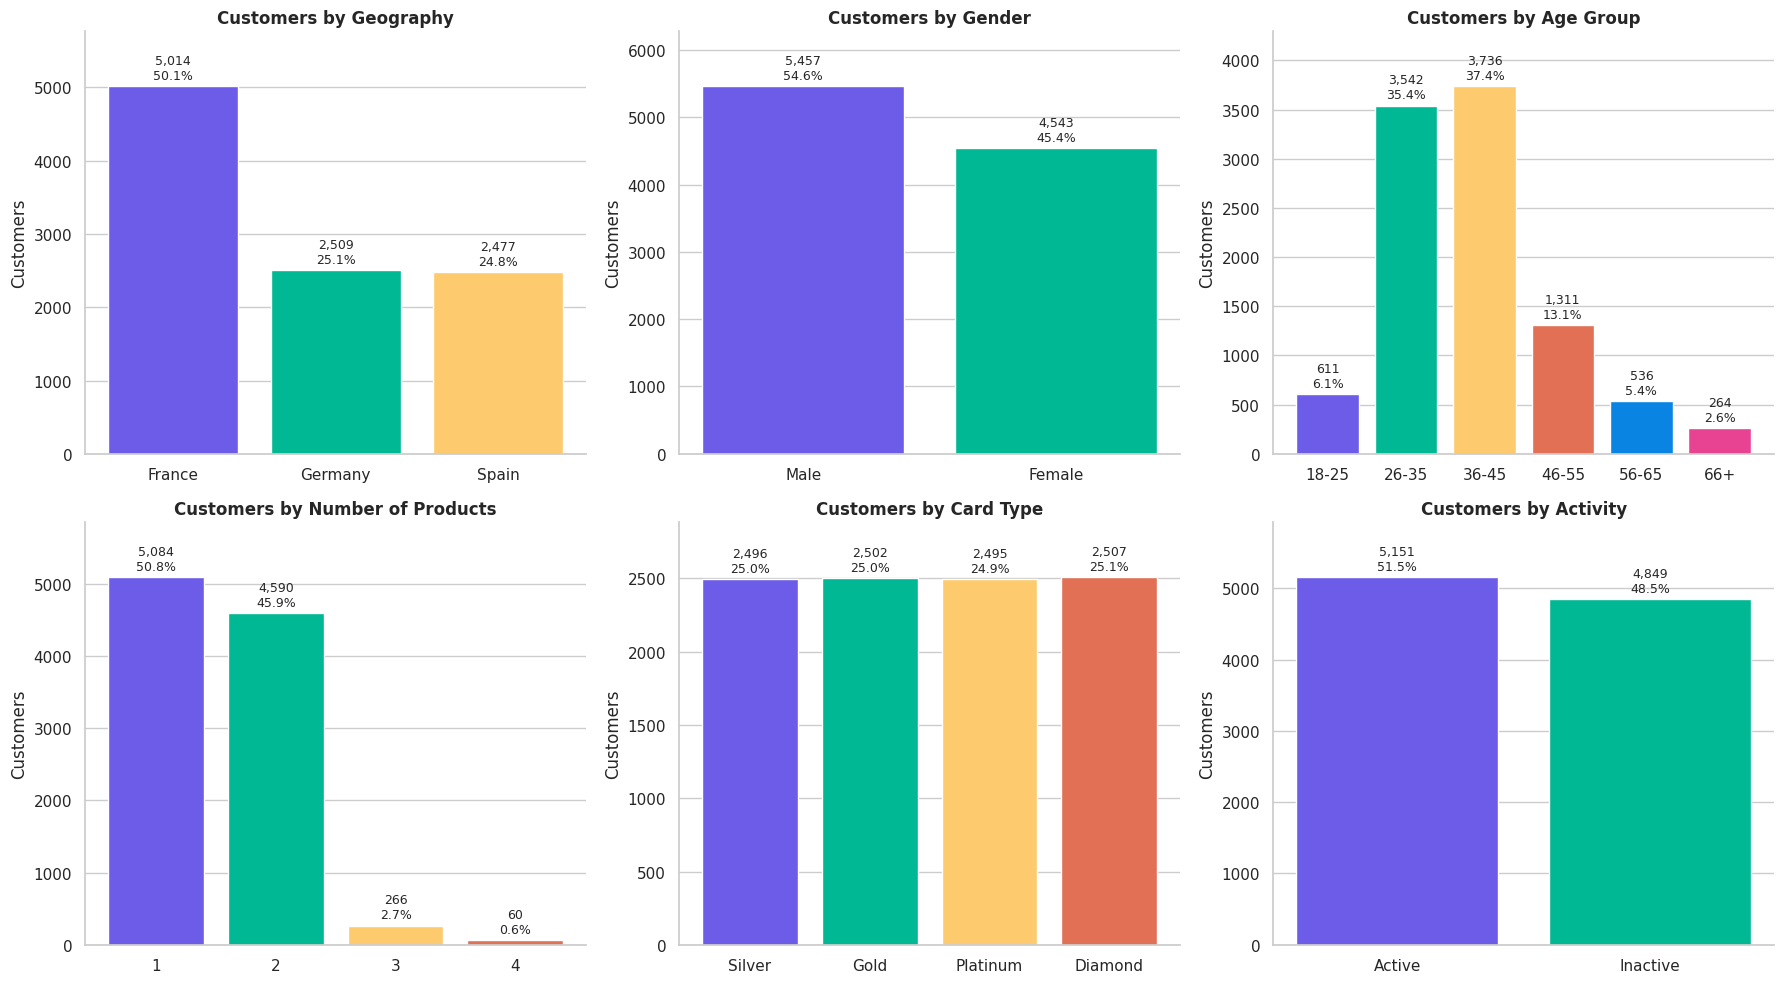

In [8]:
PALETTE = ["#6C5CE7", "#00B894", "#FDCB6E", "#E17055", "#0984E3", "#E84393", "#00CEC9", "#A29BFE"]

def bar_panel(ax, labels, values, title, xlabel="", ylabel="", colors=None, fmt="{:,.0f}", extra=None, rotation=0, ylim_pad=1.15, label_pad=3):
    """Bar chart with value labels, styled consistently across the notebook."""
    labels = [str(l) for l in labels]
    values = list(values)
    colors = colors or PALETTE[: len(labels)]
    bars = ax.bar(labels, values, color=colors)
    texts = [fmt.format(v) + (f"\n{e}" if extra is not None else "") for v, e in zip(values, extra if extra is not None else values)]
    ax.bar_label(bars, labels=texts, padding=label_pad, fontsize=9)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=rotation)
    ax.set_ylim(0, max(values) * ylim_pad if len(values) and max(values) > 0 else 1)
    sns.despine(ax=ax)

def profile(col, order=None):
    out = run_sql(f"""
    SELECT {col} AS segment, COUNT(*) AS customers,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM customers
    GROUP BY {col}
    """)
    if order is not None:
        return out.set_index("segment").reindex(order).reset_index()
    return out.sort_values("customers", ascending=False).reset_index(drop=True)

p_geo = profile("Geography", GEO_ORDER)
p_gender = profile("Gender")
p_age = profile("Age_Group", AGE_ORDER)
p_prod = profile("NumOfProducts", [1, 2, 3, 4])
p_card = profile("Card_Type", CARD_ORDER)
p_active = profile("Active", ["Active", "Inactive"])

for name, tbl in [("Geography", p_geo), ("Gender", p_gender), ("Age group", p_age),
                  ("Number of products", p_prod), ("Card type", p_card), ("Activity", p_active)]:
    print(f"Customers by {name}")
    display(tbl)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (d, title, rot) in zip(axes.flatten(), [
    (p_geo, "Customers by Geography", 0), (p_gender, "Customers by Gender", 0), (p_age, "Customers by Age Group", 0),
    (p_prod, "Customers by Number of Products", 0), (p_card, "Customers by Card Type", 0), (p_active, "Customers by Activity", 0),
]):
    bar_panel(ax, d["segment"], d["customers"], title, ylabel="Customers", extra=[f"{p:.1f}%" for p in d["pct"]], rotation=rot)
plt.tight_layout(); plt.show()

top_geo = p_geo.sort_values("customers", ascending=False).iloc[0]
FINDINGS.update({"top_geo": top_geo["segment"], "top_geo_pct": top_geo["pct"],
                 "active_pct": float(p_active.loc[p_active["segment"] == "Active", "pct"].iloc[0]),
                 "one_two_product_pct": float(p_prod.loc[p_prod["segment"].isin([1, 2]), "pct"].sum())})
show_banner(
    "How to read the customer profile",
    f"<strong>{html.escape(str(top_geo['segment']))}</strong> is the largest country ({top_geo['pct']:.1f}% of customers), "
    f"and <strong>{FINDINGS['active_pct']:.1f}%</strong> of customers are active members. "
    f"Customers with one or two products make up <strong>{FINDINGS['one_two_product_pct']:.1f}%</strong> of the base, so the 3-4 product groups are tiny "
    f"({int(p_prod.loc[p_prod['segment'].isin([3, 4]), 'customers'].sum()):,} customers) and their churn rates should be read with caution.",
    color="teal", icon="📊"
)

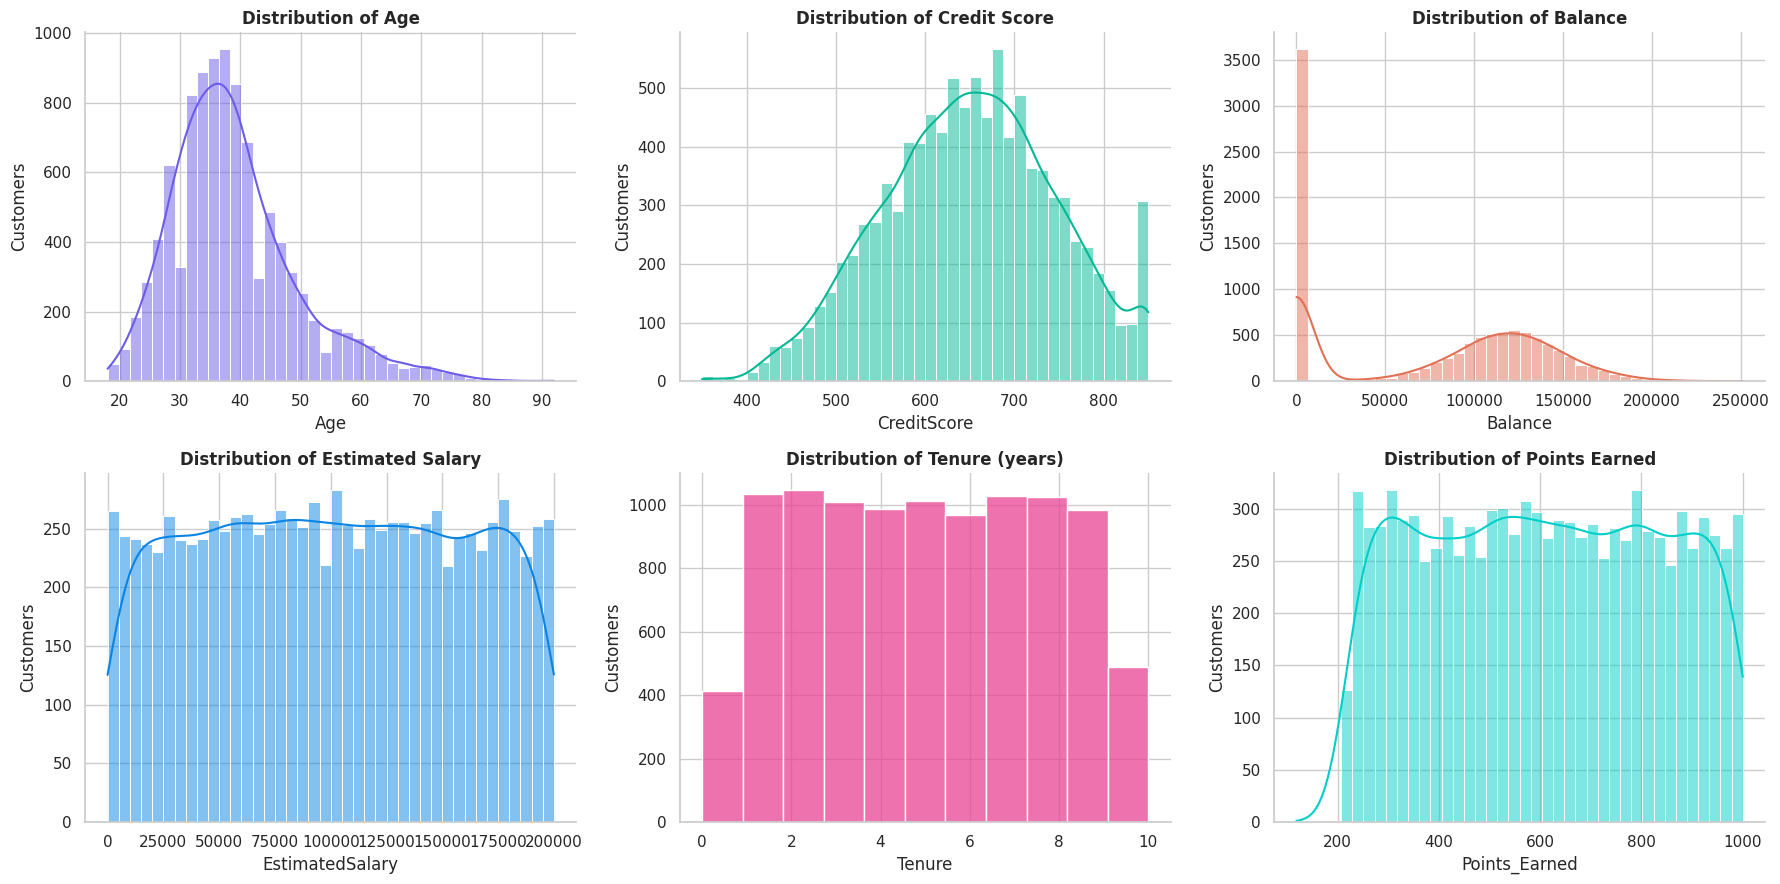

,mean,median,std,skew,min,max
Age,38.92,37.00,10.49,1.01,18.00,92.00
CreditScore,650.53,652.00,96.65,-0.07,350.00,850.00
Balance,"76,485.89","97,198.54","62,397.41",-0.14,0.00,"250,898.09"
EstimatedSalary,"100,090.24","100,193.91","57,510.49",0.00,11.58,"199,992.48"
Tenure,5.01,5.00,2.89,0.01,0.00,10.00
Points_Earned,606.52,605.00,225.92,0.01,119.00,"1,000.00"


In [9]:
# Distributions of the numeric profile
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (col, color, title) in zip(axes.flatten(), [
    ("Age", PALETTE[0], "Distribution of Age"), ("CreditScore", PALETTE[1], "Distribution of Credit Score"),
    ("Balance", PALETTE[3], "Distribution of Balance"), ("EstimatedSalary", PALETTE[4], "Distribution of Estimated Salary"),
    ("Tenure", PALETTE[5], "Distribution of Tenure (years)"), ("Points_Earned", PALETTE[6], "Distribution of Points Earned"),
]):
    sns.histplot(bank[col], bins=min(40, max(bank[col].nunique(), 5)), kde=col not in ("Tenure",), color=color, ax=ax)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(col); ax.set_ylabel("Customers")
    sns.despine(ax=ax)
plt.tight_layout(); plt.show()

num_summary = bank[["Age", "CreditScore", "Balance", "EstimatedSalary", "Tenure", "Points_Earned"]].agg(["mean", "median", "std", "skew", "min", "max"]).T
display(num_summary)

pos_bal = bank.loc[bank["Balance"] > 0, "Balance"]
show_banner(
    "How to read the distributions",
    f"Age is right-skewed (skew = {bank['Age'].skew():.2f}; median {bank['Age'].median():.0f} vs mean {bank['Age'].mean():.1f}), so a minority of older customers pulls the average up. "
    f"Balance has a large spike at 0 ({FINDINGS['zero_balance_pct']:.1f}% of customers); among customers who do hold money, the median balance is {amount(pos_bal.median())}. "
    f"Estimated salary ({amount(bank['EstimatedSalary'].min())}-{amount(bank['EstimatedSalary'].max())}) and tenure are close to evenly spread, which is unusual for real-world data and a hint that parts of this dataset are simulated.",
    color="purple", icon="🧩"
)

## 6. How many customers leave?

The target is `Exited` (1 = left, 0 = stayed). The **churn rate** is the percentage of customers who exited. It describes the scale of the problem; it does not explain why customers leave. The balances held by leavers show what is at stake financially.

,customers,exited,stayed,churn_rate_pct,total_balance,balance_of_exited,balance_share_pct,avg_balance_exited,avg_balance_stayed
value,"10,000.00","2,038.00","7,962.00",20.38,"764,858,893.00","185,681,112.00",24.28,"120,729.00","119,541.00"


,Status,customers,avg_balance_all,avg_balance_holders,pct_with_balance,avg_age
0,Stayed,7962,"72,743.00","119,541.00",60.90,37.40
1,Exited,2038,"91,109.00","120,729.00",75.50,44.80


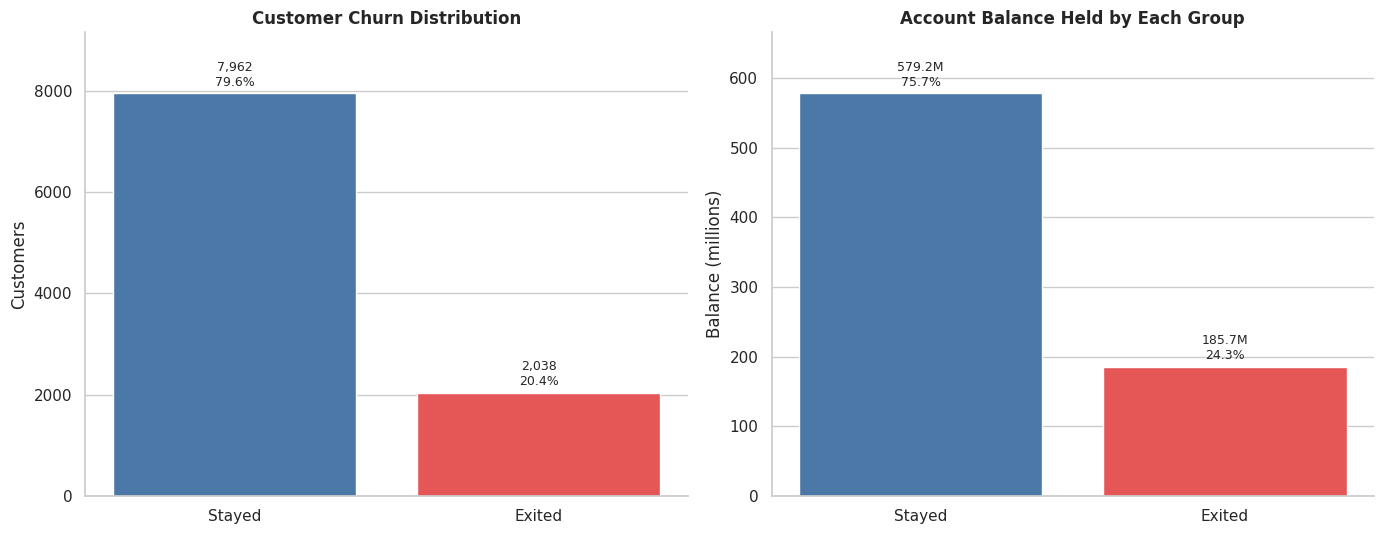

In [10]:
overall = run_sql("""
SELECT COUNT(*)                              AS customers,
       SUM(churned)                          AS exited,
       COUNT(*) - SUM(churned)               AS stayed,
       ROUND(100.0 * AVG(churned), 2)        AS churn_rate_pct,
       ROUND(SUM(Balance), 0)                AS total_balance,
       ROUND(SUM(balance_at_risk), 0)        AS balance_of_exited,
       ROUND(100.0 * SUM(balance_at_risk) / SUM(Balance), 2)  AS balance_share_pct,
       ROUND(AVG(CASE WHEN churned = 1 THEN positive_balance END), 0) AS avg_balance_exited,
       ROUND(AVG(CASE WHEN churned = 0 THEN positive_balance END), 0) AS avg_balance_stayed
FROM v_customers
""").iloc[0]
display(overall.to_frame("value").T)

OVERALL = float(overall["churn_rate_pct"])
ci_lo, ci_hi = wilson_ci(overall["exited"], overall["customers"])

group_bal = run_sql("""
SELECT Status, COUNT(*) AS customers,
       ROUND(AVG(Balance), 0)               AS avg_balance_all,
       ROUND(AVG(positive_balance), 0)      AS avg_balance_holders,
       ROUND(100.0 * AVG(Has_Balance), 1)   AS pct_with_balance,
       ROUND(AVG(Age), 1)                   AS avg_age
FROM v_customers
GROUP BY Status
ORDER BY Status DESC
""")
display(group_bal)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
bar_panel(axes[0], ["Stayed", "Exited"], [overall["stayed"], overall["exited"]], "Customer Churn Distribution",
          ylabel="Customers", colors=["#4C78A8", "#E45756"],
          extra=[f"{100 - OVERALL:.1f}%", f"{OVERALL:.1f}%"])
bar_panel(axes[1], ["Stayed", "Exited"], [(overall["total_balance"] - overall["balance_of_exited"]) / 1e6, overall["balance_of_exited"] / 1e6],
          "Account Balance Held by Each Group", ylabel="Balance (millions)", fmt="{:,.1f}M", colors=["#4C78A8", "#E45756"],
          extra=[f"{100 - overall['balance_share_pct']:.1f}%", f"{overall['balance_share_pct']:.1f}%"])
plt.tight_layout(); plt.show()

FINDINGS.update({"churn_rate": OVERALL, "exited": int(overall["exited"]), "customers": int(overall["customers"]),
                 "balance_of_exited": float(overall["balance_of_exited"]), "balance_share": float(overall["balance_share_pct"]),
                 "total_balance": float(overall["total_balance"])})

show_cards([
    {"title": "Churn rate", "body": f"<strong>{OVERALL:.2f}%</strong> of customers exited<br>95% CI {ci_lo:.1f}% to {ci_hi:.1f}%", "color": "red", "icon": "📉"},
    {"title": "Customers lost", "body": f"<strong>{int(overall['exited']):,}</strong> of <strong>{int(overall['customers']):,}</strong> customers<br>about 1 in {100/OVERALL:.1f}", "color": "orange", "icon": "🚪"},
    {"title": "Balance that left", "body": f"<strong>{amount(overall['balance_of_exited']/1e6, 1)}M</strong> held by leavers<br><strong>{overall['balance_share_pct']:.1f}%</strong> of all balances", "color": "purple", "icon": "💰"},
    {"title": "Class imbalance", "body": f"Churners are the minority class (<strong>{OVERALL:.1f}%</strong>). A model that predicts 'stays' for everyone is <strong>{100-OVERALL:.1f}%</strong> accurate but finds no churners.", "color": "blue", "icon": "⚖️"},
], columns=4)

show_banner(
    "Churn costs more balance than its headcount suggests" if overall["balance_share_pct"] > OVERALL else "Churn costs less balance than its headcount suggests",
    f"Leavers are <strong>{OVERALL:.1f}%</strong> of customers but hold <strong>{overall['balance_share_pct']:.1f}%</strong> of all balances. "
    f"Among customers who hold money, leavers and stayers carry similar average balances (<strong>{amount(overall['avg_balance_exited'])}</strong> vs "
    f"<strong>{amount(overall['avg_balance_stayed'])}</strong>); the difference is that <strong>{group_bal.loc[group_bal['Status']=='Exited','pct_with_balance'].iloc[0]:.1f}%</strong> of leavers hold a positive balance "
    f"versus <strong>{group_bal.loc[group_bal['Status']=='Stayed','pct_with_balance'].iloc[0]:.1f}%</strong> of stayers. "
    "A churn score is a prioritisation signal, not proof that a customer will leave or that an action will prevent it.",
    color="red", icon="💸"
)

## 7. Churn by customer segment

For each segment, calculate customers, number exited and **churn rate** (`exited ÷ customers in the segment`), with a 95% Wilson confidence interval. The dashed line on each chart is the overall churn rate; **red bars are above it and blue bars at or below it**.

**How to read this section:** compare the *percentage* who left within each group, not the number who left. A group with a higher churn rate may be worth investigating, but a small group can have an unstable rate and should not automatically be prioritised; the confidence interval shows how stable each rate is.

Churn by Geography


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,France,5014,811,16.17,50.14,"57,759,182.00",15.18,17.22,-4.21
1,Germany,2509,814,32.44,25.09,"97,973,916.00",30.64,34.30,12.06
2,Spain,2477,413,16.67,24.77,"29,948,015.00",15.26,18.19,-3.71


Churn by Gender


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,Female,4543,1139,25.07,45.43,"101,412,732.00",23.83,26.35,4.69
1,Male,5457,899,16.47,54.57,"84,268,380.00",15.51,17.48,-3.91


Churn by Activity status


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,Active,5151,735,14.27,51.51,"67,120,668.00",13.34,15.25,-6.11
1,Inactive,4849,1303,26.87,48.49,"118,560,444.00",25.64,28.14,6.49


... (6 outputs left out)

Churn by Tenure band


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,0-1 yrs,1448,327,22.58,14.48,"29,969,005.00",20.50,24.81,2.20
1,2-4 yrs,3046,617,20.26,30.46,"54,017,759.00",18.87,21.72,-0.12
2,5-7 yrs,3007,582,19.35,30.07,"52,955,073.00",17.98,20.81,-1.03
3,8-10 yrs,2499,512,20.49,24.99,"48,739,275.00",18.95,22.12,0.11


Churn by Satisfaction score


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,1,1932,387,20.03,19.32,"36,015,969.00",18.31,21.87,-0.35
1,2,2014,439,21.80,20.14,"40,218,176.00",20.05,23.65,1.42
2,3,2042,401,19.64,20.42,"34,843,197.00",17.97,21.42,-0.74
3,4,2008,414,20.62,20.08,"38,670,969.00",18.90,22.44,0.24
4,5,2004,397,19.81,20.04,"35,932,801.00",18.12,21.61,-0.57


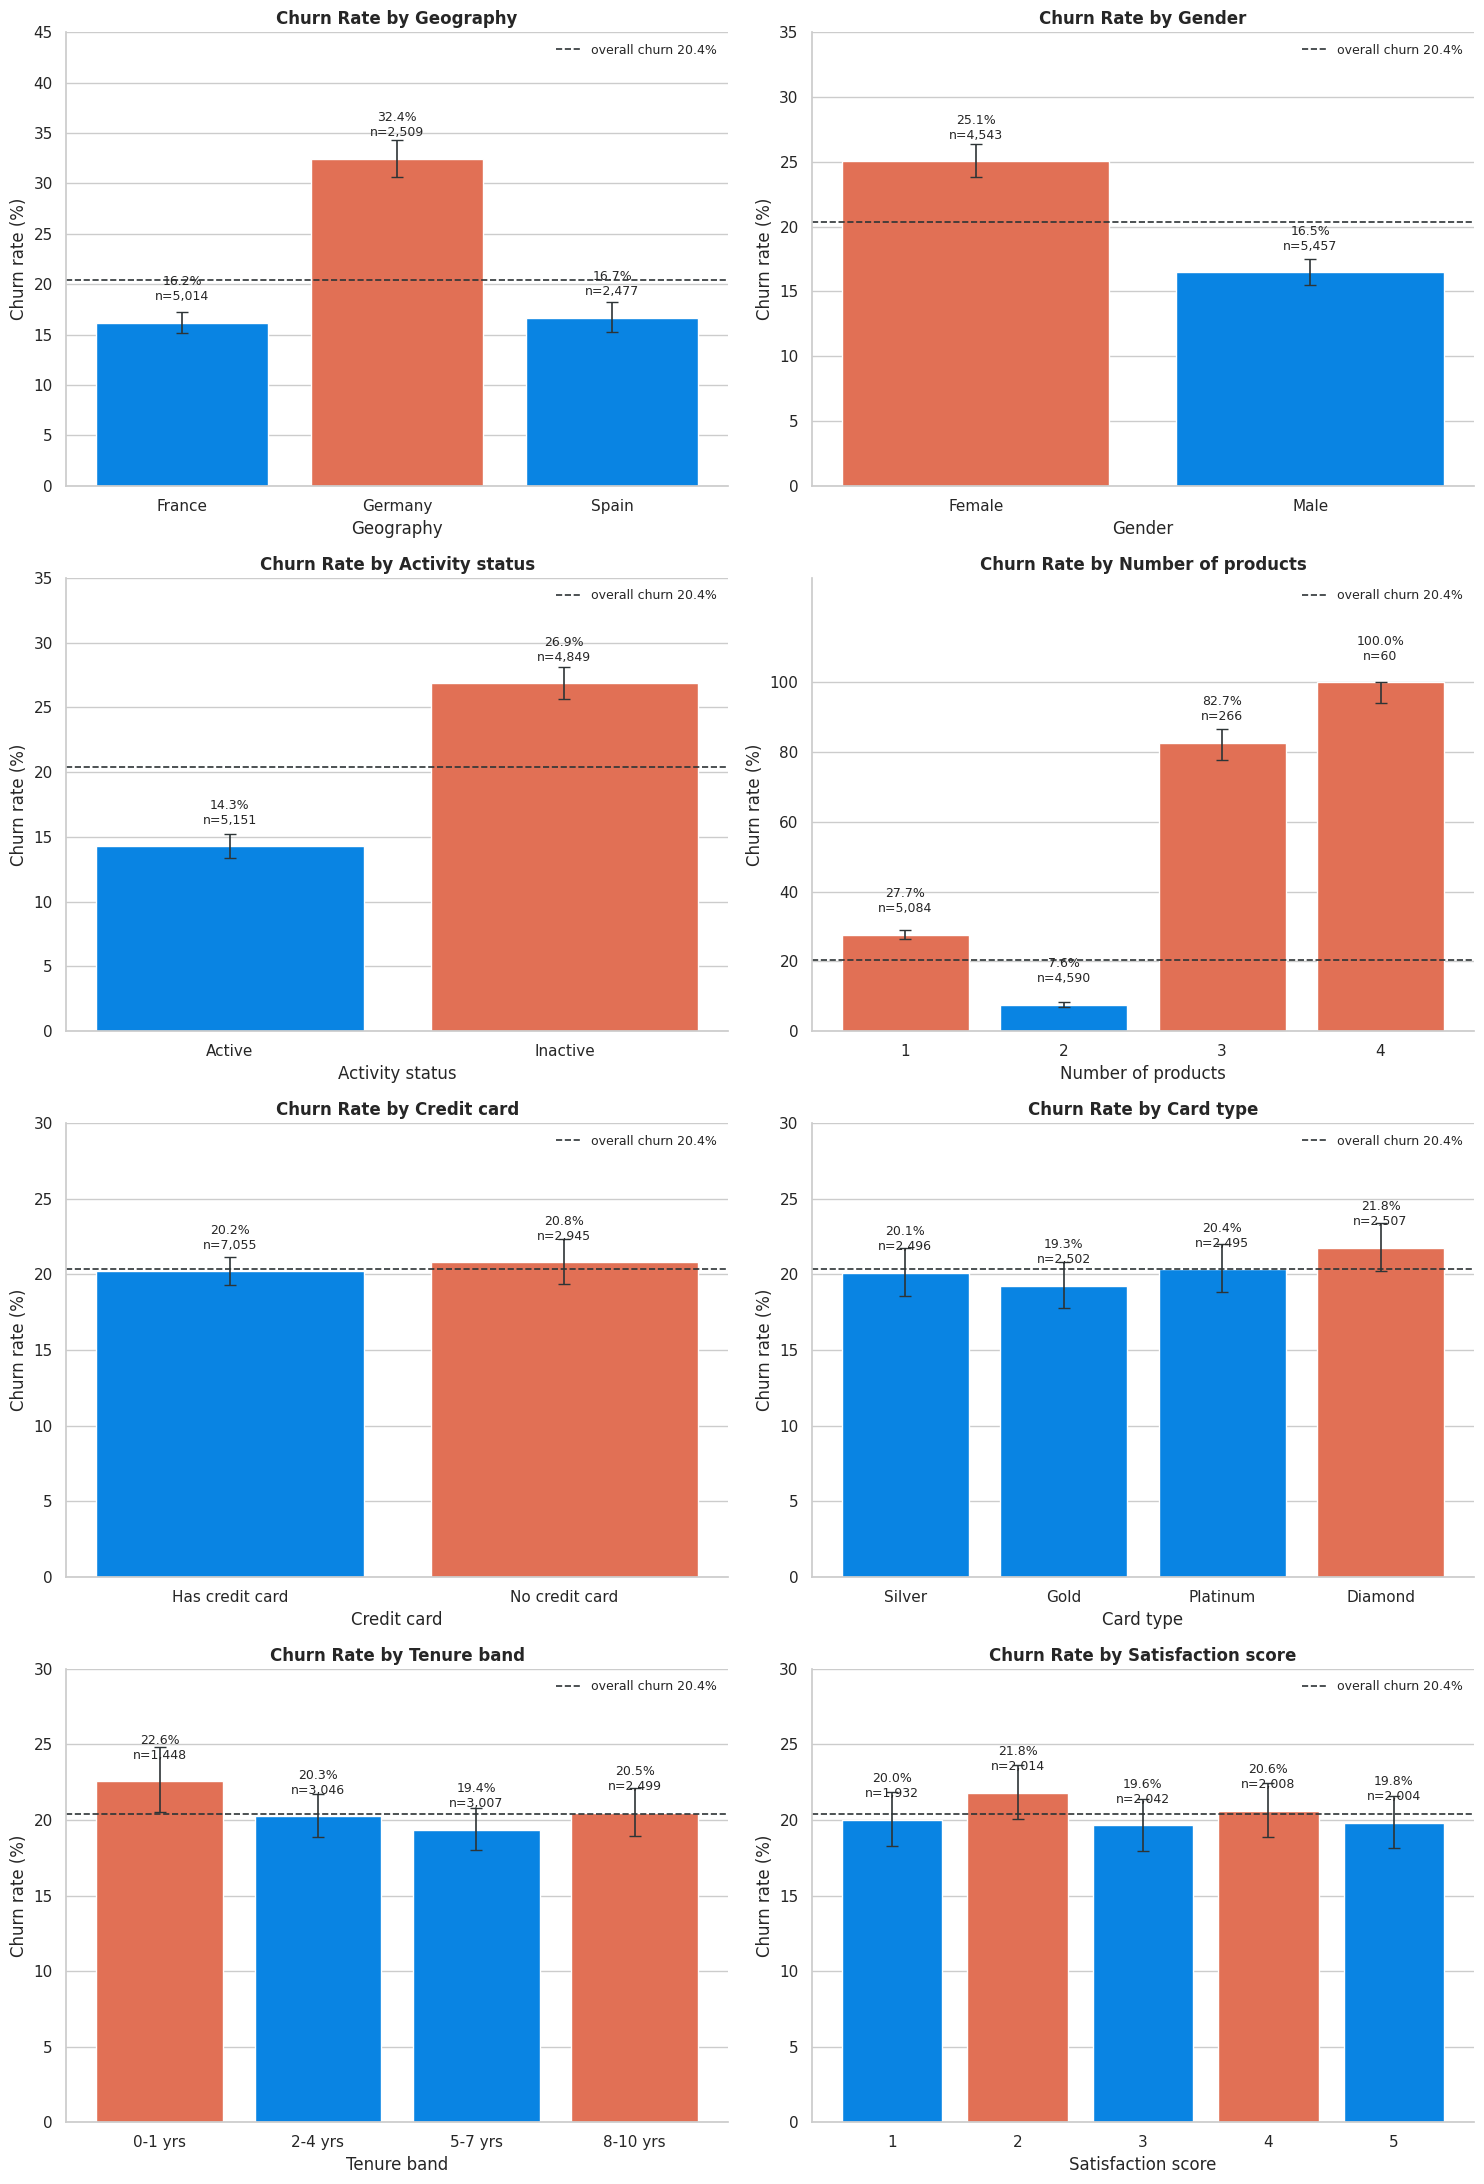

In [11]:
def churn_by(expr, order=None, where=""):
    """Churn summary per segment, computed in SQL, with Wilson 95% CI and gap to the overall rate."""
    out = run_sql(f"""
    SELECT {expr} AS segment,
           COUNT(*)                                            AS customers,
           SUM(churned)                                        AS exited,
           ROUND(100.0 * AVG(churned), 2)                      AS churn_rate_pct,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)  AS share_pct,
           ROUND(SUM(balance_at_risk), 0)                      AS balance_of_exited
    FROM v_customers
    {where}
    GROUP BY 1
    """)
    if order is not None:
        out = out.set_index("segment").reindex(order).reset_index()
    else:
        out = out.sort_values("segment").reset_index(drop=True)
    ci = [wilson_ci(e, n) for e, n in zip(out["exited"], out["customers"])]
    out["ci_low_%"] = [c[0] for c in ci]
    out["ci_high_%"] = [c[1] for c in ci]
    out["vs_overall_pp"] = out["churn_rate_pct"] - OVERALL
    return out

def churn_panel(ax, tbl, title, xlabel="", rotation=0):
    """Churn-rate bars: red above the overall rate, blue at or below, with CI whiskers and the overall rate as a dashed line."""
    colors = ["#E17055" if r > OVERALL else "#0984E3" for r in tbl["churn_rate_pct"]]
    bar_panel(ax, tbl["segment"], tbl["churn_rate_pct"], title, xlabel=xlabel, ylabel="Churn rate (%)", fmt="{:.1f}%",
              colors=colors, extra=[f"n={n:,.0f}" for n in tbl["customers"]], rotation=rotation, ylim_pad=1.3, label_pad=14)
    # Wilson intervals are not centred on the raw rate, and at extreme rates (e.g. 100%) the bound can fall just inside it, so clip at 0
    err = np.clip(np.array([tbl["churn_rate_pct"] - tbl["ci_low_%"], tbl["ci_high_%"] - tbl["churn_rate_pct"]]), 0, None)
    ax.errorbar(range(len(tbl)), tbl["churn_rate_pct"], yerr=err, fmt="none", ecolor="#2D3436", capsize=4, linewidth=1.2)
    ax.axhline(OVERALL, color="#2D3436", linestyle="--", linewidth=1.2, label=f"overall churn {OVERALL:.1f}%")
    ax.set_yticks([t for t in ax.get_yticks() if t <= 100])          # a rate cannot exceed 100%
    ax.legend(loc="upper right", fontsize=9, frameon=False)

seg_specs = [
    ("Geography", "Geography", GEO_ORDER, 0),
    ("Gender", "Gender", ["Female", "Male"], 0),
    ("Active", "Activity status", ["Active", "Inactive"], 0),
    ("NumOfProducts", "Number of products", [1, 2, 3, 4], 0),
    ("Credit_Card", "Credit card", ["Has credit card", "No credit card"], 0),
    ("Card_Type", "Card type", CARD_ORDER, 0),
    ("Tenure_Band", "Tenure band", TENURE_ORDER, 0),
    ("Satisfaction_Score", "Satisfaction score", [1, 2, 3, 4, 5], 0),
]
seg_tables = {}
for col, label, order, _ in seg_specs:
    seg_tables[col] = churn_by(col, order)
    print(f"Churn by {label}")
    display(seg_tables[col])

fig, axes = plt.subplots(4, 2, figsize=(15, 22))
for ax, (col, label, order, rot) in zip(axes.flatten(), seg_specs):
    churn_panel(ax, seg_tables[col], f"Churn Rate by {label}", xlabel=label, rotation=rot)
plt.tight_layout(); plt.show()

,Dimension,Highest-churn group,Highest rate (%),Lowest-churn group,Lowest rate (%),Spread (pp)
0,Number of products,3,82.71,2,7.60,75.11
1,Geography,Germany,32.44,France,16.17,16.27
2,Activity status,Inactive,26.87,Active,14.27,12.60
3,Gender,Female,25.07,Male,16.47,8.60
4,Tenure band,0-1 yrs,22.58,5-7 yrs,19.35,3.23
5,Card type,Diamond,21.78,Gold,19.26,2.52
6,Satisfaction score,2,21.80,3,19.64,2.16
7,Credit card,No credit card,20.81,Has credit card,20.20,0.61


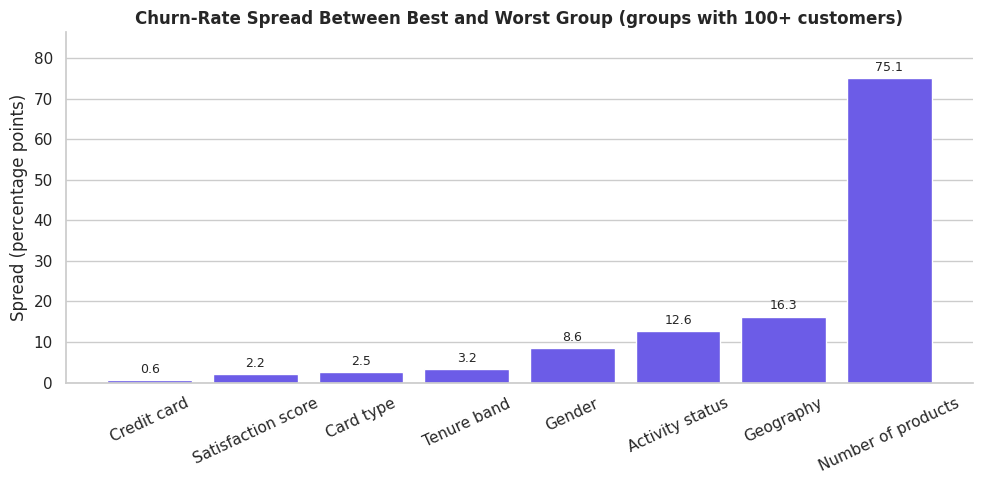

In [12]:
# Which dimension separates churn the most?
def seg_label(v):
    """Show 3.0 as 3 (integer segments become floats after a reindex or row selection)."""
    return str(int(v)) if isinstance(v, (float, np.floating)) and float(v).is_integer() else str(v)

spread_rows = []
for col, label, order, _ in seg_specs:
    t = seg_tables[col]
    big = t[t["customers"] >= 100]                       # ignore tiny groups when ranking
    hi, lo = big.loc[big["churn_rate_pct"].idxmax()], big.loc[big["churn_rate_pct"].idxmin()]
    spread_rows.append({"Dimension": label, "Highest-churn group": seg_label(hi["segment"]), "Highest rate (%)": hi["churn_rate_pct"],
                        "Lowest-churn group": seg_label(lo["segment"]), "Lowest rate (%)": lo["churn_rate_pct"],
                        "Spread (pp)": hi["churn_rate_pct"] - lo["churn_rate_pct"]})
spread_df = pd.DataFrame(spread_rows).sort_values("Spread (pp)", ascending=False).reset_index(drop=True)
display(spread_df)

fig, ax = plt.subplots(figsize=(10, 5))
bar_panel(ax, spread_df["Dimension"][::-1], spread_df["Spread (pp)"][::-1], "Churn-Rate Spread Between Best and Worst Group (groups with 100+ customers)",
          ylabel="Spread (percentage points)", fmt="{:.1f}", colors=["#6C5CE7"] * len(spread_df), rotation=25)
plt.tight_layout(); plt.show()

flat_dims = spread_df.loc[spread_df["Spread (pp)"] < 3, "Dimension"].tolist()
top1, top2 = spread_df.iloc[0], spread_df.iloc[1]
ng = seg_tables["NumOfProducts"].set_index("segment")
geo = seg_tables["Geography"].set_index("segment")
gen = seg_tables["Gender"].set_index("segment")
act = seg_tables["Active"].set_index("segment")
FINDINGS.update({
    "spread_top": top1["Dimension"], "spread_top_pp": top1["Spread (pp)"], "flat_dims": flat_dims,
    "geo_hi": geo["churn_rate_pct"].idxmax(), "geo_hi_rate": geo["churn_rate_pct"].max(), "geo_lo_rate": geo["churn_rate_pct"].min(),
    "female_rate": gen.loc["Female", "churn_rate_pct"], "male_rate": gen.loc["Male", "churn_rate_pct"],
    "inactive_rate": act.loc["Inactive", "churn_rate_pct"], "active_rate": act.loc["Active", "churn_rate_pct"],
    "prod1_rate": ng.loc[1, "churn_rate_pct"], "prod2_rate": ng.loc[2, "churn_rate_pct"],
    "prod3_rate": ng.loc[3, "churn_rate_pct"], "prod4_rate": ng.loc[4, "churn_rate_pct"],
    "prod3_n": int(ng.loc[3, "customers"]), "prod4_n": int(ng.loc[4, "customers"]),
})

show_banner(
    "What the segment comparison shows",
    f"<ul><li><strong>{html.escape(str(top1['Dimension']))}</strong> separates churn most ({top1['Spread (pp)']:.1f} pp between {html.escape(str(top1['Highest-churn group']))} at {top1['Highest rate (%)']:.1f}% "
    f"and {html.escape(str(top1['Lowest-churn group']))} at {top1['Lowest rate (%)']:.1f}%), followed by <strong>{html.escape(str(top2['Dimension']))}</strong> ({top2['Spread (pp)']:.1f} pp).</li>"
    f"<li><strong>Product count is not linear</strong>: churn is {FINDINGS['prod1_rate']:.1f}% with 1 product, <strong>{FINDINGS['prod2_rate']:.1f}%</strong> with 2, then jumps to "
    f"{FINDINGS['prod3_rate']:.1f}% with 3 and {FINDINGS['prod4_rate']:.1f}% with 4 (only {FINDINGS['prod3_n']:,} and {FINDINGS['prod4_n']:,} customers).</li>"
    f"<li><strong>{html.escape(str(FINDINGS['geo_hi']))}</strong> churns at {FINDINGS['geo_hi_rate']:.1f}% against {FINDINGS['geo_lo_rate']:.1f}% in the lowest country; "
    f"women churn at {FINDINGS['female_rate']:.1f}% vs {FINDINGS['male_rate']:.1f}% for men; inactive members at {FINDINGS['inactive_rate']:.1f}% vs {FINDINGS['active_rate']:.1f}% for active members.</li>"
    f"<li>Little or no difference (under 3 pp) for: <strong>{html.escape(', '.join(flat_dims)) or 'none'}</strong>.</li></ul>"
    "These are descriptive differences between overlapping groups (for example Germany and inactive members may overlap). Section 12 separates their independent contributions.",
    color="blue", icon="💡"
)

## 8. Age and financial profile

Age and money-related variables are continuous, so they are grouped into bands for communication. **Band boundaries are choices** and can hide variation inside a band, so each band's churn rate is shown with its confidence interval, and the continuous distributions are compared directly afterwards.

Churn by Age group


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,18-25,611,46,7.53,6.11,"4,383,045.00",5.69,9.90,-12.85
1,26-35,3542,301,8.50,35.42,"28,086,670.00",7.62,9.46,-11.88
2,36-45,3736,734,19.65,37.36,"67,471,016.00",18.40,20.95,-0.73
3,46-55,1311,663,50.57,13.11,"59,323,326.00",47.87,53.27,30.19
4,56-65,536,259,48.32,5.36,"23,216,260.00",44.12,52.55,27.94
5,66+,264,35,13.26,2.64,"3,200,795.00",9.69,17.88,-7.12


Churn by Credit score band


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,Poor (<580),2362,520,22.02,23.62,"47,116,753.00",20.39,23.73,1.64
1,Fair (580-669),3331,685,20.56,33.31,"62,276,442.00",19.23,21.97,0.18
2,Good (670-739),2428,452,18.62,24.28,"40,706,207.00",17.12,20.21,-1.76
3,Very good (740-799),1224,253,20.67,12.24,"23,651,144.00",18.49,23.03,0.29
4,Exceptional (800+),655,128,19.54,6.55,"11,930,566.00",16.69,22.75,-0.84


Churn by Balance band


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,No balance,3617,500,13.82,36.17,0.00,12.74,14.99,-6.56
1,Q1 Low,1596,330,20.68,15.96,"26,491,731.00",18.76,22.73,0.30
2,Q2 Mid-low,1596,437,27.38,15.96,"48,385,785.00",25.25,29.62,7.00
3,Q3 Mid-high,1595,404,25.33,15.95,"52,089,228.00",23.26,27.52,4.95
4,Q4 High,1596,367,22.99,15.96,"58,714,368.00",21.00,25.12,2.61


Churn by Salary band


,segment,customers,exited,churn_rate_pct,share_pct,balance_of_exited,ci_low_%,ci_high_%,vs_overall_pp
0,Q1 Low,2500,500,20.00,25.00,"46,454,837.00",18.48,21.61,-0.38
1,Q2 Mid-low,2500,495,19.80,25.00,"44,277,871.00",18.28,21.41,-0.58
2,Q3 Mid-high,2500,503,20.12,25.00,"45,939,077.00",18.59,21.74,-0.26
3,Q4 High,2500,540,21.60,25.00,"49,009,327.00",20.03,23.26,1.22


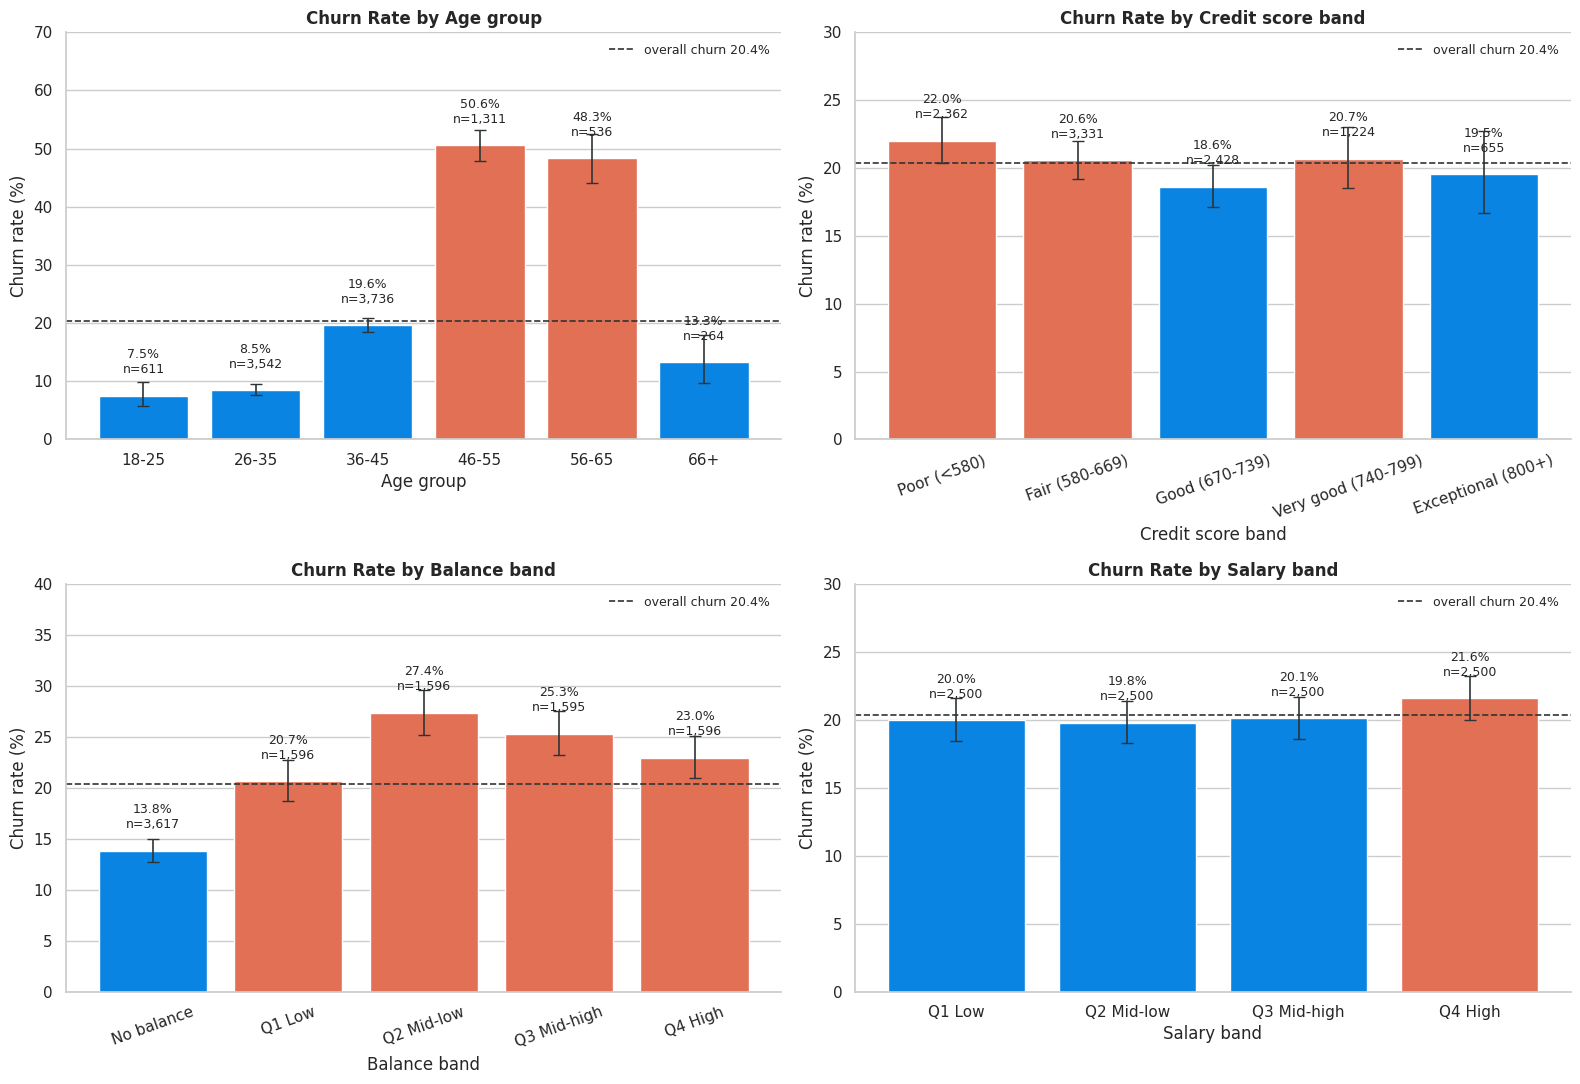

In [13]:
band_specs = [
    ("Age_Group", "Age group", AGE_ORDER, 0),
    ("Credit_Band", "Credit score band", CREDIT_ORDER, 20),
    ("Balance_Band", "Balance band", BALANCE_ORDER, 20),
    ("Salary_Band", "Salary band", QUART_ORDER, 0),
]
band_tables = {}
for col, label, order, _ in band_specs:
    band_tables[col] = churn_by(col, order)
    print(f"Churn by {label}")
    display(band_tables[col])

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (col, label, order, rot) in zip(axes.flatten(), band_specs):
    churn_panel(ax, band_tables[col], f"Churn Rate by {label}", xlabel=label, rotation=rot)
plt.tight_layout(); plt.show()

at = band_tables["Age_Group"].set_index("segment")
bt = band_tables["Balance_Band"].set_index("segment")
ct = band_tables["Credit_Band"].set_index("segment")
st = band_tables["Salary_Band"]
peak_age = at["churn_rate_pct"].idxmax()
FINDINGS.update({
    "peak_age_group": peak_age, "peak_age_rate": at.loc[peak_age, "churn_rate_pct"],
    "young_rate": at.loc["18-25", "churn_rate_pct"], "senior_rate": at.loc["66+", "churn_rate_pct"],
    "age_spread_pp": at["churn_rate_pct"].max() - at["churn_rate_pct"].min(),
    "nobal_rate": bt.loc["No balance", "churn_rate_pct"], "hibal_rate": bt.loc["Q4 High", "churn_rate_pct"],
    "credit_spread_pp": ct["churn_rate_pct"].max() - ct["churn_rate_pct"].min(),
    "salary_spread_pp": st["churn_rate_pct"].max() - st["churn_rate_pct"].min(),
})
show_banner(
    "What the age and financial bands show",
    f"<ul><li><strong>Age shows a strong, non-linear pattern</strong>: churn peaks in the <strong>{html.escape(str(peak_age))}</strong> group at {FINDINGS['peak_age_rate']:.1f}%, "
    f"compared with {FINDINGS['young_rate']:.1f}% for ages 18-25 and {FINDINGS['senior_rate']:.1f}% for 66+. Older customers are <em>not</em> uniformly more loyal: the relationship is a hump, not a straight line.</li>"
    f"<li><strong>Balance</strong>: customers with no balance churn at {FINDINGS['nobal_rate']:.1f}%, while every positive-balance quartile churns more, including {FINDINGS['hibal_rate']:.1f}% in the highest quartile, "
    "so large balances are <em>not</em> a sign of loyalty here.</li>"
    f"<li><strong>Credit score</strong> ({FINDINGS['credit_spread_pp']:.1f} pp spread) and <strong>salary</strong> ({FINDINGS['salary_spread_pp']:.1f} pp spread) show little difference.</li></ul>",
    color="green", icon="📈"
)

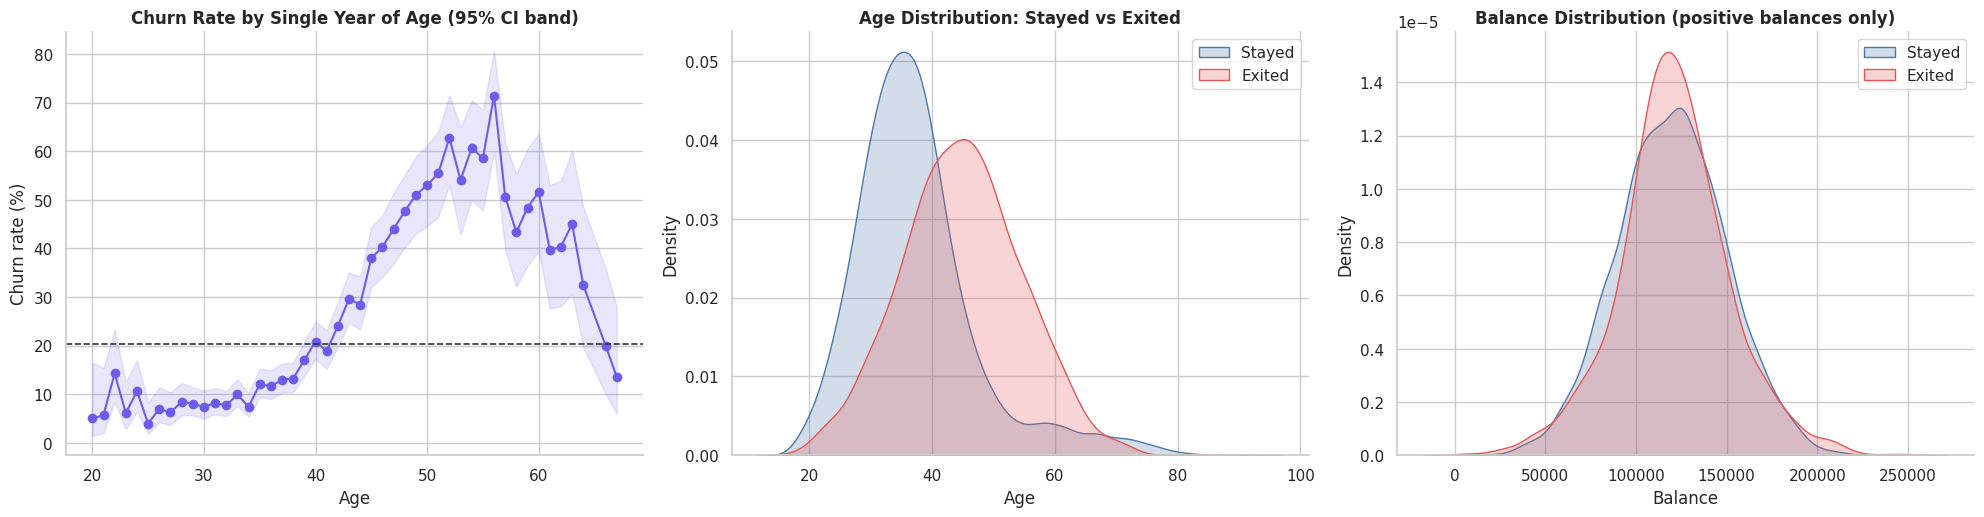

In [14]:
# Age: continuous view
age_year = churn_by("Age")
age_year = age_year[age_year["customers"] >= 30]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].plot(age_year["segment"], age_year["churn_rate_pct"], marker="o", color="#6C5CE7")
axes[0].fill_between(age_year["segment"], age_year["ci_low_%"], age_year["ci_high_%"], color="#6C5CE7", alpha=0.15)
axes[0].axhline(OVERALL, color="#2D3436", linestyle="--", linewidth=1.2)
axes[0].set_title("Churn Rate by Single Year of Age (95% CI band)", fontweight="bold")
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Churn rate (%)")

for status, color in [("Stayed", "#4C78A8"), ("Exited", "#E45756")]:
    sns.kdeplot(bank.loc[bank["Status"] == status, "Age"], ax=axes[1], color=color, fill=True, alpha=0.25, label=status)
axes[1].set_title("Age Distribution: Stayed vs Exited", fontweight="bold"); axes[1].set_xlabel("Age"); axes[1].legend()

for status, color in [("Stayed", "#4C78A8"), ("Exited", "#E45756")]:
    sub = bank.loc[(bank["Status"] == status) & (bank["Balance"] > 0), "Balance"]
    sns.kdeplot(sub, ax=axes[2], color=color, fill=True, alpha=0.25, label=status)
axes[2].set_title("Balance Distribution (positive balances only)", fontweight="bold"); axes[2].set_xlabel("Balance"); axes[2].legend()
for ax in axes: sns.despine(ax=ax)
plt.tight_layout(); plt.show()

age_year = age_year.reset_index(drop=True)
age_year["smoothed_%"] = age_year["churn_rate_pct"].rolling(5, center=True, min_periods=3).mean()     # 5-year window removes single-year noise
peak_year = age_year.loc[age_year["smoothed_%"].idxmax()]
med_age = bank.groupby("Status")["Age"].median()
FINDINGS.update({"median_age_exited": med_age["Exited"], "median_age_stayed": med_age["Stayed"]})
show_banner(
    "Reading the age curve",
    f"The median exiting customer is <strong>{med_age['Exited']:.0f}</strong> years old versus <strong>{med_age['Stayed']:.0f}</strong> for those who stayed. "
    f"Year-by-year churn rises through the 40s and, smoothed over five-year windows, peaks around age <strong>{int(peak_year['segment'])}</strong> ({peak_year['smoothed_%']:.0f}%) before falling again in the 60s. "
    "A straight-line assumption (older = more loyal, as the dataset notes suggest) would miss this, which is why age is modelled with flexible models later.",
    color="purple", icon="🎂"
)

## 9. Combined effects: product count, activity, geography and gender

Single-variable comparisons overlap. The charts below cross two variables at a time to show where churn concentrates, and to check whether one pattern is only a stand-in for another.

**How to read the heatmaps:** each cell is the churn rate of customers in that combination; darker red means more churn. Cells with fewer than 30 customers are left blank because their rates are unreliable.

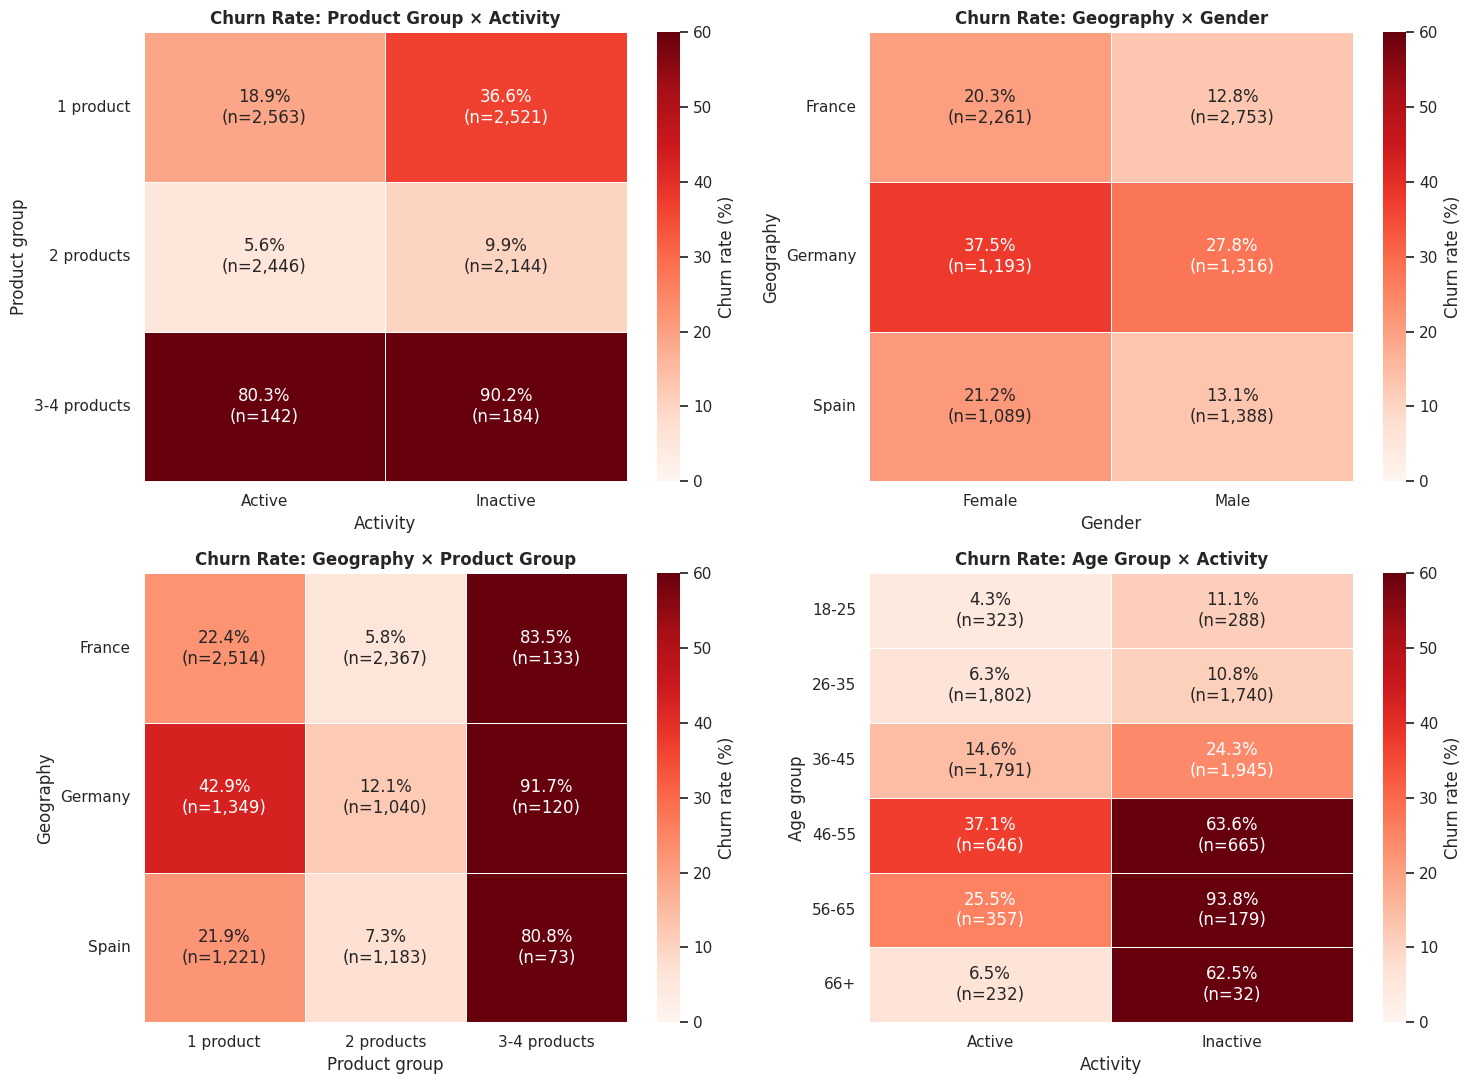

In [15]:
def churn_matrix(row, col, row_order, col_order, min_n=30):
    q = run_sql(f"""
    SELECT {row} AS r, {col} AS c, COUNT(*) AS n, ROUND(100.0 * AVG(churned), 2) AS rate
    FROM v_customers GROUP BY 1, 2
    """)
    rate = q.pivot(index="r", columns="c", values="rate").reindex(index=row_order, columns=col_order)
    n = q.pivot(index="r", columns="c", values="n").reindex(index=row_order, columns=col_order)
    return rate.where(n >= min_n), n

def heat(ax, rate, n, title, xlabel, ylabel):
    annot = rate.copy().astype(object)
    for r in rate.index:
        for c in rate.columns:
            annot.loc[r, c] = "n<30" if pd.isna(rate.loc[r, c]) else f"{rate.loc[r, c]:.1f}%\n(n={int(n.loc[r, c]):,})"
    sns.heatmap(rate.astype(float), annot=annot, fmt="", cmap="Reds", vmin=0, vmax=60, linewidths=0.5, cbar_kws={"label": "Churn rate (%)"}, ax=ax)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    plt.setp(ax.get_yticklabels(), rotation=0)

m_prod_act, n_prod_act = churn_matrix("Product_Group", "Active", PRODUCT_ORDER, ["Active", "Inactive"])
m_geo_gen, n_geo_gen = churn_matrix("Geography", "Gender", GEO_ORDER, ["Female", "Male"])
m_geo_prod, n_geo_prod = churn_matrix("Geography", "Product_Group", GEO_ORDER, PRODUCT_ORDER)
m_age_act, n_age_act = churn_matrix("Age_Group", "Active", AGE_ORDER, ["Active", "Inactive"])

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
heat(axes[0, 0], m_prod_act, n_prod_act, "Churn Rate: Product Group × Activity", "Activity", "Product group")
heat(axes[0, 1], m_geo_gen, n_geo_gen, "Churn Rate: Geography × Gender", "Gender", "Geography")
heat(axes[1, 0], m_geo_prod, n_geo_prod, "Churn Rate: Geography × Product Group", "Product group", "Geography")
heat(axes[1, 1], m_age_act, n_age_act, "Churn Rate: Age Group × Activity", "Activity", "Age group")
plt.tight_layout(); plt.show()

FINDINGS.update({
    "two_prod_active": m_prod_act.loc["2 products", "Active"], "two_prod_inactive": m_prod_act.loc["2 products", "Inactive"],
    "one_prod_inactive": m_prod_act.loc["1 product", "Inactive"], "one_prod_active": m_prod_act.loc["1 product", "Active"],
    "age_4655_active": m_age_act.loc["46-55", "Active"], "age_4655_inactive": m_age_act.loc["46-55", "Inactive"],
})
show_banner(
    "What the combinations reveal",
    f"<ul><li><strong>Activity matters inside every product group</strong>: with one product, inactive customers churn at {FINDINGS['one_prod_inactive']:.1f}% vs {FINDINGS['one_prod_active']:.1f}% for active ones; "
    f"customers with two products are the safest group ({FINDINGS['two_prod_active']:.1f}% when active).</li>"
    f"<li><strong>Middle-aged customers are the pressure point</strong>: in the 46-55 band, inactive customers churn at {FINDINGS['age_4655_inactive']:.1f}% vs {FINDINGS['age_4655_active']:.1f}% for active ones.</li>"
    "<li>The geography and gender gaps persist inside most combinations, so they are not just a side effect of one another.</li></ul>",
    color="orange", icon="🔥"
)

,Geography,customers,pct_with_balance,avg_positive_balance,avg_age,pct_active,pct_3plus_products,churn_rate_pct
0,France,5014,51.80,"119,928.00",38.50,51.70,2.70,16.17
1,Germany,2509,100.00,"119,730.00",39.80,49.70,4.80,32.44
2,Spain,2477,51.60,"119,815.00",38.90,53.00,2.90,16.67


,Geography,balance_status,customers,churn_rate_pct
0,France,No balance,2418,13.94
1,France,Has balance,2596,18.26
2,Germany,Has balance,2509,32.44
3,Spain,No balance,1199,13.59
4,Spain,Has balance,1278,19.56


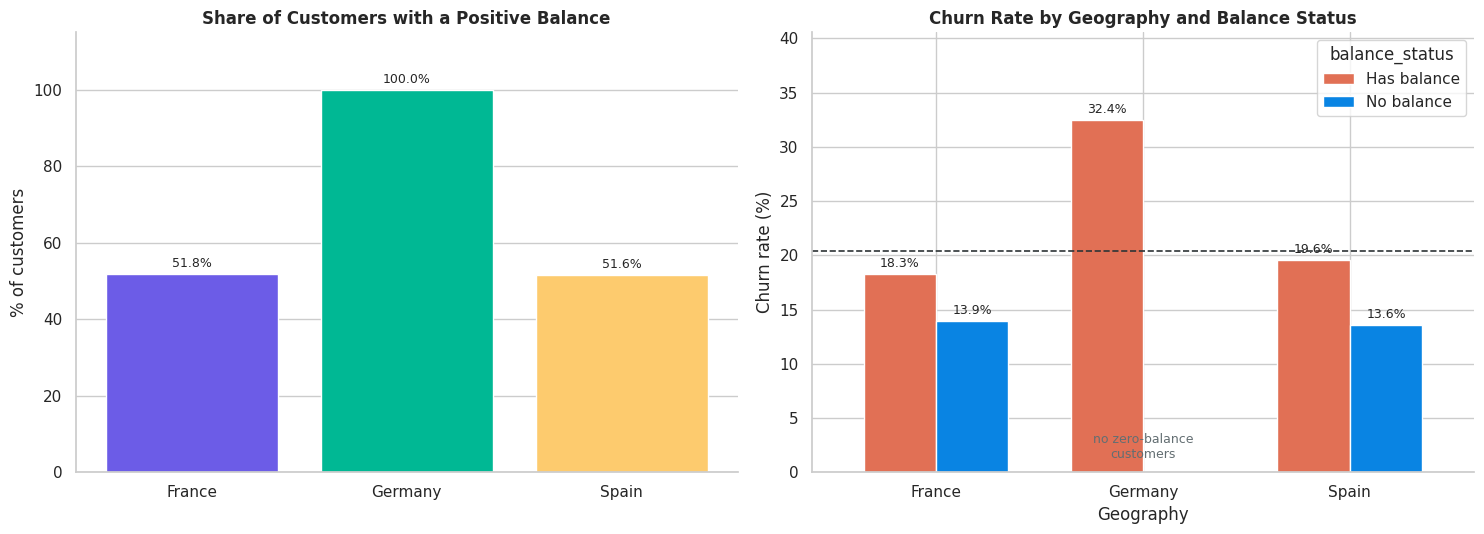

In [16]:
# The Germany pattern: is it a geography effect or a balance effect?
geo_profile = run_sql("""
SELECT Geography,
       COUNT(*)                                       AS customers,
       ROUND(100.0 * AVG(Has_Balance), 1)             AS pct_with_balance,
       ROUND(AVG(positive_balance), 0)                AS avg_positive_balance,
       ROUND(AVG(Age), 1)                             AS avg_age,
       ROUND(100.0 * AVG(IsActiveMember), 1)          AS pct_active,
       ROUND(100.0 * AVG(CASE WHEN NumOfProducts >= 3 THEN 1.0 ELSE 0 END), 1) AS pct_3plus_products,
       ROUND(100.0 * AVG(churned), 2)                 AS churn_rate_pct
FROM v_customers
GROUP BY Geography
ORDER BY Geography
""")
display(geo_profile)

geo_bal = run_sql("""
SELECT Geography, CASE WHEN Has_Balance = 1 THEN 'Has balance' ELSE 'No balance' END AS balance_status,
       COUNT(*) AS customers, ROUND(100.0 * AVG(churned), 2) AS churn_rate_pct
FROM v_customers
GROUP BY Geography, Has_Balance
ORDER BY Geography, Has_Balance
""")
display(geo_bal)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
bar_panel(axes[0], geo_profile["Geography"], geo_profile["pct_with_balance"], "Share of Customers with a Positive Balance", ylabel="% of customers", fmt="{:.1f}%")
piv = geo_bal.pivot(index="Geography", columns="balance_status", values="churn_rate_pct").reindex(GEO_ORDER)
piv.plot(kind="bar", ax=axes[1], color=["#E17055", "#0984E3"], rot=0, width=0.7)
for cont, status_col in zip(axes[1].containers, piv.columns):
    axes[1].bar_label(cont, labels=["" if pd.isna(v) else f"{v:.1f}%" for v in piv[status_col]], padding=3, fontsize=9)
axes[1].text(1, 1, "no zero-balance\ncustomers", ha="center", va="bottom", fontsize=9, color="#636e72")
axes[1].axhline(OVERALL, color="#2D3436", linestyle="--", linewidth=1.2)
axes[1].set_title("Churn Rate by Geography and Balance Status", fontweight="bold"); axes[1].set_ylabel("Churn rate (%)")
axes[1].set_ylim(0, piv.max().max() * 1.25); sns.despine(ax=axes[1])
plt.tight_layout(); plt.show()

g = geo_profile.set_index("Geography")
gb = geo_bal.set_index(["Geography", "balance_status"])["churn_rate_pct"]
FINDINGS.update({"germany_pct_balance": g.loc["Germany", "pct_with_balance"],
                 "france_pct_balance": g.loc["France", "pct_with_balance"],
                 "germany_hasbal_rate": gb[("Germany", "Has balance")],
                 "france_hasbal_rate": gb[("France", "Has balance")], "spain_hasbal_rate": gb[("Spain", "Has balance")]})
show_banner(
    "Germany: a balance effect or a location effect?",
    f"<strong>{g.loc['Germany', 'pct_with_balance']:.1f}%</strong> of German customers hold a positive balance, against only <strong>{g.loc['France', 'pct_with_balance']:.1f}%</strong> of French and "
    f"<strong>{g.loc['Spain', 'pct_with_balance']:.1f}%</strong> of Spanish customers, and customers with a balance churn more than those without one in France and Spain. "
    "Balance status therefore explains part of Germany's higher overall rate, so the fair comparison is among customers <em>with</em> a balance: "
    f"Germany still churns at <strong>{FINDINGS['germany_hasbal_rate']:.1f}%</strong> vs {FINDINGS['france_hasbal_rate']:.1f}% in France and {FINDINGS['spain_hasbal_rate']:.1f}% in Spain. "
    "The country gap is not simply a balance effect, although the data cannot say whether it reflects pricing, competition or service in Germany.",
    color="teal", icon="🌍"
)

## 10. Complaints and satisfaction: early-warning signal or leakage?

`Complain` and `Satisfaction_Score` are the two columns most likely to be affected by **timing**. A complaint recorded *after* a customer has decided to leave cannot be used to predict that departure. This section measures how strongly they relate to churn, and how the satisfaction score behaves, before deciding whether they may be used for modelling.

,Complained,customers,exited,churn_rate_pct,share_pct,balance_of_exited
0,No complaint,7956,4,0.05,79.56,"479,682.00"
1,Complained,2044,2034,99.51,20.44,"185,201,430.00"


Complained,churn % (Complained),churn % (No complaint)
Satisfaction_Score,,
1,99.74,0.06
2,99.77,0.13
3,98.77,0.00
4,100.00,0.06
5,99.25,0.00


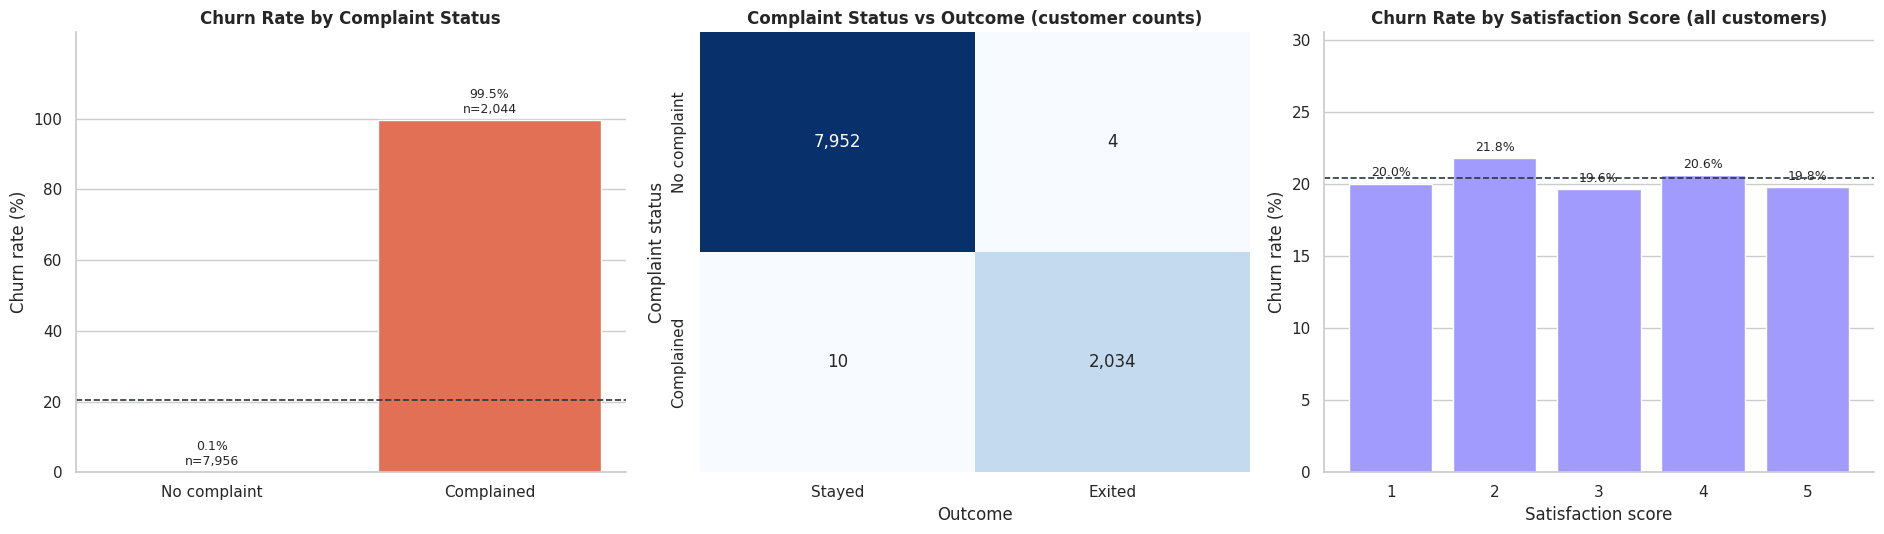

In [17]:
complain_tbl = run_sql("""
SELECT Complained,
       COUNT(*)                                              AS customers,
       SUM(churned)                                          AS exited,
       ROUND(100.0 * AVG(churned), 2)                        AS churn_rate_pct,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)    AS share_pct,
       ROUND(SUM(balance_at_risk), 0)                        AS balance_of_exited
FROM v_customers
GROUP BY Complained
ORDER BY Complained DESC
""")
display(complain_tbl)

# Satisfaction score among customers who complained vs those who did not
sat_tbl = run_sql("""
SELECT Complained, Satisfaction_Score, COUNT(*) AS customers, ROUND(100.0 * AVG(churned), 2) AS churn_rate_pct
FROM v_customers
GROUP BY Complained, Satisfaction_Score
ORDER BY Complained, Satisfaction_Score
""")
display(sat_tbl.pivot(index="Satisfaction_Score", columns="Complained", values="churn_rate_pct").rename(columns=lambda c: f"churn % ({c})"))

# How well does "complained" alone reproduce the outcome?
tp = int(((bank["Complain"] == 1) & (bank["Exited"] == 1)).sum())
fp = int(((bank["Complain"] == 1) & (bank["Exited"] == 0)).sum())
fn = int(((bank["Complain"] == 0) & (bank["Exited"] == 1)).sum())
tn = int(((bank["Complain"] == 0) & (bank["Exited"] == 0)).sum())
rule_acc = (tp + tn) / len(bank)
rule_prec = tp / (tp + fp)
rule_rec = tp / (tp + fn)

# Satisfaction score: any relationship with churn?
chi2_s, p_s, dof_s, v_s = cramers_v(pd.crosstab(bank["Satisfaction_Score"], bank["Exited"]))
sat_complainers = bank[bank["Complain"] == 1]
chi2_sc, p_sc, dof_sc, v_sc = cramers_v(pd.crosstab(sat_complainers["Satisfaction_Score"], sat_complainers["Exited"]))

c_yes = complain_tbl.set_index("Complained").loc["Complained"]
c_no = complain_tbl.set_index("Complained").loc["No complaint"]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
bar_panel(axes[0], ["No complaint", "Complained"], [c_no["churn_rate_pct"], c_yes["churn_rate_pct"]], "Churn Rate by Complaint Status",
          ylabel="Churn rate (%)", fmt="{:.1f}%", colors=["#0984E3", "#E17055"], extra=[f"n={int(c_no['customers']):,}", f"n={int(c_yes['customers']):,}"], ylim_pad=1.25)
axes[0].axhline(OVERALL, color="#2D3436", linestyle="--", linewidth=1.2)
axes[0].set_yticks([t for t in axes[0].get_yticks() if t <= 100])

cm = np.array([[tn, fn], [fp, tp]])          # rows = complaint status, columns = outcome
sns.heatmap(cm, annot=[[f"{v:,}" for v in row] for row in cm], fmt="", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Stayed", "Exited"], yticklabels=["No complaint", "Complained"])
axes[1].set_title("Complaint Status vs Outcome (customer counts)", fontweight="bold"); axes[1].set_xlabel("Outcome"); axes[1].set_ylabel("Complaint status")

sat_all = seg_tables["Satisfaction_Score"]
bar_panel(axes[2], sat_all["segment"], sat_all["churn_rate_pct"], "Churn Rate by Satisfaction Score (all customers)", xlabel="Satisfaction score",
          ylabel="Churn rate (%)", fmt="{:.1f}%", colors=["#A29BFE"] * len(sat_all), ylim_pad=1.4)
axes[2].axhline(OVERALL, color="#2D3436", linestyle="--", linewidth=1.2)
plt.tight_layout(); plt.show()

FINDINGS.update({"complain_churn": c_yes["churn_rate_pct"], "nocomplain_churn": c_no["churn_rate_pct"], "complain_share": c_yes["share_pct"],
                 "complain_rule_acc": rule_acc * 100, "complain_rule_prec": rule_prec * 100, "complain_rule_rec": rule_rec * 100,
                 "sat_p": p_s, "sat_v": v_s, "sat_p_complainers": p_sc,
                 "complain_exit_share": tp / int(bank["Exited"].sum()) * 100})

show_cards([
    {"title": "Complainers churn almost always", "body": f"<strong>{c_yes['churn_rate_pct']:.1f}%</strong> of the {int(c_yes['customers']):,} customers with a complaint exited, vs <strong>{c_no['churn_rate_pct']:.2f}%</strong> of the {int(c_no['customers']):,} without one.", "color": "red", "icon": "📣"},
    {"title": "One column reproduces the target", "body": f"'Complained = will exit' alone is <strong>{rule_acc*100:.1f}%</strong> accurate, with precision <strong>{rule_prec*100:.1f}%</strong> and recall <strong>{rule_rec*100:.1f}%</strong>.", "color": "orange", "icon": "🎯"},
    {"title": "Satisfaction score is flat", "body": f"Churn is almost identical at every score (Cramér's V = {v_s:.3f}, p {html.escape(fmt_p(p_s))}); among complainers only, p {html.escape(fmt_p(p_sc))}.", "color": "blue", "icon": "⭐"},
], columns=3)

show_banner(
    "Complain is treated as leakage; Satisfaction Score as uninformative",
    f"<code>Complain</code> separates churn almost perfectly ({c_yes['churn_rate_pct']:.1f}% vs {c_no['churn_rate_pct']:.2f}%). No behavioural variable behaves this way: the complaint is very likely "
    "<strong>recorded as part of the exit</strong> (for example a complaint logged when the customer closes the account), so using it to predict churn would be circular. "
    f"It is <strong>excluded from the predictive model</strong> and its effect is reported only here. <code>Satisfaction_Score</code> shows no relationship with churn "
    f"(p {html.escape(fmt_p(p_s))}) and is recorded even for customers with no complaint, so it is also kept out of the model. "
    "Before either column is used operationally, its recording date and business definition should be confirmed with the data owner.",
    color="red", icon="🚨"
)

## 11. Statistical tests: which patterns warrant further investigation?

Visual differences are useful leads. Statistical tests quantify the evidence against "no association", and **effect sizes** show whether a difference is large enough to matter.

<div style="display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:12px;margin:12px 0">
<div style="background:#EDE9FE;border-top:5px solid #7C3AED;border-radius:12px;padding:14px"><strong style="color:#6D28D9">Chi-square test</strong><br>Checks whether a categorical variable is associated with churn. Effect size: <strong>Cramér's V</strong> (0 = none, 1 = perfect).</div>
<div style="background:#DBEAFE;border-top:5px solid #2563EB;border-radius:12px;padding:14px"><strong style="color:#1D4ED8">Mann–Whitney U</strong><br>Compares the distribution of a numeric variable between leavers and stayers without assuming normality. Effect size: <strong>rank-biserial r</strong>.</div>
<div style="background:#DCFCE7;border-top:5px solid #16A34A;border-radius:12px;padding:14px"><strong style="color:#15803D">Benjamini–Hochberg</strong><br>Adjusts p-values (q-values) for running many tests at once, so that some "significant" results are not just chance.</div>
</div>

> **Reading rule.** With 10,000 customers even tiny differences reach p < 0.05. Use the **effect size** to judge importance: Cramér's V below 0.10 or |r| below 0.10 is negligible.

,Variable,Test,Statistic,p-value,q-value (BH),Significant (q<0.05),Effect size,Effect measure,Effect size class,Detail
0,Complain (leakage),Chi-square,"9,914.04",<0.001,<0.001,Yes,1.00,Cramér's V,large,dof = 1
1,Age (numeric),Mann–Whitney U,"11,878,815.00",<0.001,<0.001,Yes,0.46,|rank-biserial r|,medium,median exited 45.0 vs stayed 36.0
2,Number of products,Chi-square,"1,501.50",<0.001,<0.001,Yes,0.39,Cramér's V,medium,dof = 3
3,Geography,Chi-square,300.63,<0.001,<0.001,Yes,0.17,Cramér's V,small,dof = 2
4,Active member,Chi-square,244.47,<0.001,<0.001,Yes,0.16,Cramér's V,small,dof = 1
5,Balance (numeric),Mann–Whitney U,"9,373,909.50",<0.001,<0.001,Yes,0.16,|rank-biserial r|,small,"median exited 109,344.2 vs stayed 92,063.1"
6,Gender,Chi-square,112.93,<0.001,<0.001,Yes,0.11,Cramér's V,small,dof = 1
7,Tenure (as categories),Chi-square,14.06,0.170,0.236,No,0.04,Cramér's V,negligible,dof = 10
8,Credit score (numeric),Mann–Whitney U,"7,846,429.50",0.022,0.041,Yes,0.03,|rank-biserial r|,negligible,median exited 646.0 vs stayed 653.0
9,Card type,Chi-square,5.05,0.168,0.236,No,0.02,Cramér's V,negligible,dof = 3


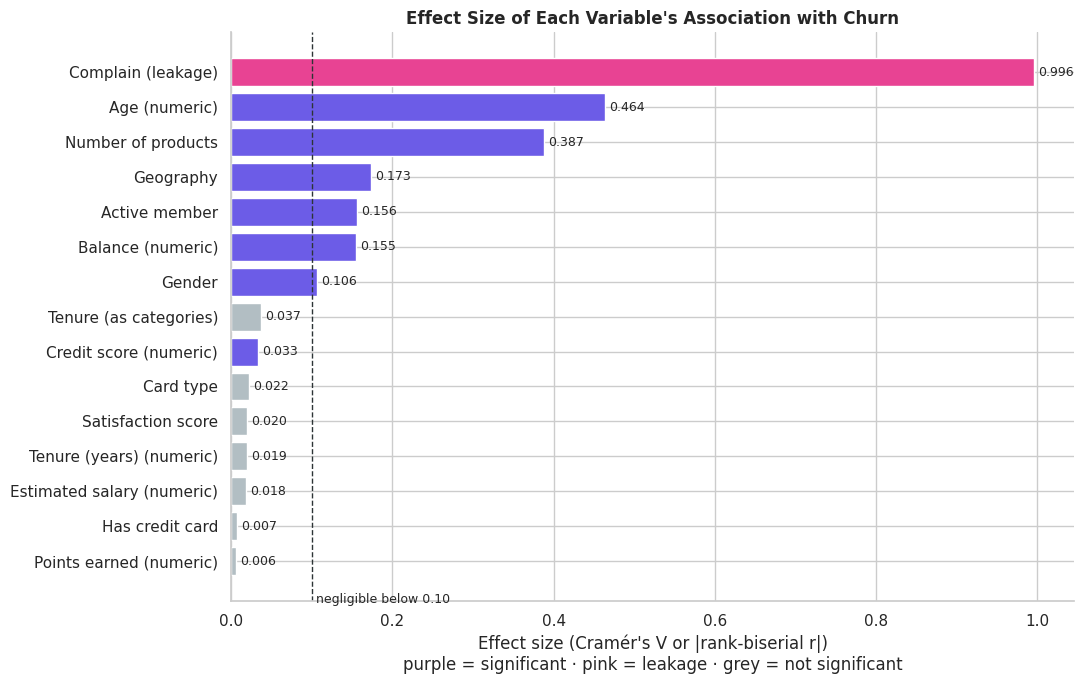

In [18]:
cat_tests = [("Geography", "Geography"), ("Gender", "Gender"), ("HasCrCard", "Has credit card"), ("IsActiveMember", "Active member"),
             ("NumOfProducts", "Number of products"), ("Card_Type", "Card type"), ("Tenure", "Tenure (as categories)"),
             ("Satisfaction_Score", "Satisfaction score"), ("Complain", "Complain (leakage)")]
num_tests = [("Age", "Age"), ("Balance", "Balance"), ("CreditScore", "Credit score"), ("EstimatedSalary", "Estimated salary"),
             ("Tenure", "Tenure (years)"), ("Points_Earned", "Points earned")]

rows = []
for col, label in cat_tests:
    chi2, p, dof, v = cramers_v(pd.crosstab(bank[col], bank["Exited"]))
    rows.append({"Variable": label, "Test": "Chi-square", "Statistic": chi2, "p-value": p, "Effect size": v,
                 "Effect measure": "Cramér's V", "Detail": f"dof = {dof}"})

for col, label in num_tests:
    a, b = bank.loc[bank["Exited"] == 1, col], bank.loc[bank["Exited"] == 0, col]
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 2 * u / (len(a) * len(b)) - 1                       # rank-biserial: >0 means exited tend to be higher
    rows.append({"Variable": label + " (numeric)", "Test": "Mann–Whitney U", "Statistic": u, "p-value": p, "Effect size": abs(r_rb),
                 "Effect measure": "|rank-biserial r|",
                 "Detail": f"median exited {a.median():,.1f} vs stayed {b.median():,.1f}"})

tests = pd.DataFrame(rows)
tests["q-value (BH)"] = benjamini_hochberg(tests["p-value"].values)
tests["Significant (q<0.05)"] = np.where(tests["q-value (BH)"] < 0.05, "Yes", "No")

def size_label(x):
    return "negligible" if x < 0.10 else ("small" if x < 0.30 else ("medium" if x < 0.50 else "large"))
tests["Effect size class"] = tests["Effect size"].map(size_label)
tests = tests.sort_values("Effect size", ascending=False).reset_index(drop=True)

display_tests = tests.copy()
display_tests["p-value"] = display_tests["p-value"].map(fmt_p)
display_tests["q-value (BH)"] = display_tests["q-value (BH)"].map(fmt_p)
display(display_tests[["Variable", "Test", "Statistic", "p-value", "q-value (BH)", "Significant (q<0.05)", "Effect size", "Effect measure", "Effect size class", "Detail"]])

colors_t = ["#B2BEC3" if s == "No" else ("#E84393" if "leakage" in v else "#6C5CE7") for s, v in zip(tests["Significant (q<0.05)"], tests["Variable"])]
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(tests["Variable"][::-1], tests["Effect size"][::-1], color=colors_t[::-1])
ax.bar_label(bars, labels=[f"{v:.3f}" for v in tests["Effect size"][::-1]], padding=3, fontsize=9)
ax.axvline(0.10, color="#2D3436", linestyle="--", linewidth=1)
ax.text(0.10, -0.9, " negligible below 0.10", fontsize=9, va="top")
ax.set_title("Effect Size of Each Variable's Association with Churn", fontweight="bold")
ax.set_xlabel("Effect size (Cramér's V or |rank-biserial r|)\npurple = significant · pink = leakage · grey = not significant"); sns.despine()
plt.tight_layout(); plt.show()

clean = tests[~tests["Variable"].str.contains("leakage")]
sig_meaningful = clean[(clean["Significant (q<0.05)"] == "Yes") & (clean["Effect size"] >= 0.10)]["Variable"].tolist()
sig_negligible = clean[(clean["Significant (q<0.05)"] == "Yes") & (clean["Effect size"] < 0.10)]["Variable"].tolist()
not_sig = clean[clean["Significant (q<0.05)"] == "No"]["Variable"].tolist()
FINDINGS.update({"sig_meaningful": sig_meaningful, "sig_negligible": sig_negligible, "not_sig": not_sig})

show_banner(
    "What the tests show",
    f"<ul><li><strong>Meaningful associations</strong> (significant and effect size ≥ 0.10, excluding leakage): <strong>{html.escape(', '.join(sig_meaningful)) or 'none'}</strong>.</li>"
    f"<li><strong>Significant but negligible</strong> (effect size &lt; 0.10): {html.escape(', '.join(sig_negligible)) or 'none'}. Statistically detectable, commercially small.</li>"
    f"<li><strong>No detectable association</strong> after adjustment: {html.escape(', '.join(not_sig)) or 'none'}.</li></ul>"
    "Tenure appears twice because the two tests ask different questions (any pattern across the 11 tenure values vs a shift in the typical tenure). "
    "None of these tests proves a cause.",
    color="purple", icon="🧪"
)

## 12. Independent drivers: logistic regression

Many segments overlap (inactive customers are older, German customers hold larger balances, and so on). A **logistic regression** estimates each variable's association with churn *while holding the others constant*. Results are shown as **odds ratios**: 1.0 = no association, above 1 = higher odds of leaving, below 1 = lower odds.

- Numeric variables are standardised, so their odds ratio is **per 1 standard deviation increase**.
- Categorical variables are compared with a **reference group** (stated in each label).
- `Complain` and `Satisfaction_Score` are excluded (Section 10).
- 95% confidence intervals come from **300 bootstrap resamples** of the customers, which needs no extra libraries and makes no normality assumption.

,Variable,Odds ratio,CI low,CI high,Significant (CI excludes 1)
0,Product Group: 3-4 products (vs 2 products),79.81,59.51,115.81,Yes
1,Age Group: 56-65 (vs 36-45),5.09,4.21,6.49,Yes
2,Product Group: 1 product (vs 2 products),4.71,4.07,5.62,Yes
3,Age Group: 46-55 (vs 36-45),4.37,3.80,5.06,Yes
4,Geography: Germany (vs France),2.66,2.27,3.11,Yes
5,Gender: Female (vs Male),1.67,1.47,1.87,Yes
6,Balance (per 1 SD),1.11,0.93,1.29,No
7,EstimatedSalary (per 1 SD),1.03,0.97,1.10,No
8,Geography: Spain (vs France),1.03,0.89,1.20,No
9,Card Type: Diamond (vs Silver),1.01,0.87,1.17,No


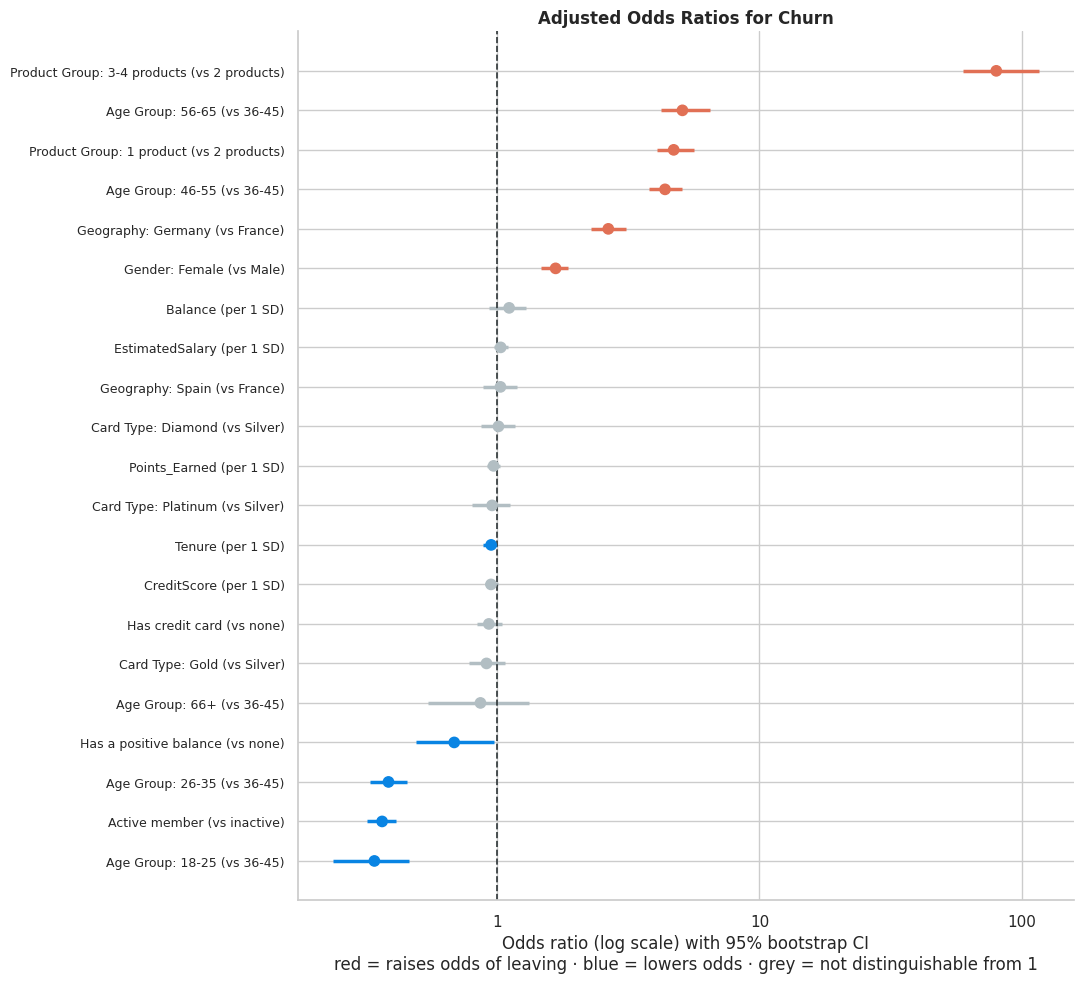

In [19]:
ref_levels = {"Geography": "France", "Gender": "Male", "Age_Group": "36-45", "Product_Group": "2 products", "Card_Type": "Silver"}
cat_cols_lr = list(ref_levels)
num_cols_lr = ["CreditScore", "Balance", "EstimatedSalary", "Tenure", "Points_Earned"]
bin_cols_lr = ["Has_Balance", "IsActiveMember", "HasCrCard"]

def design_matrix(frame):
    parts = [frame[bin_cols_lr].astype(float)]
    num = (frame[num_cols_lr] - bank[num_cols_lr].mean()) / bank[num_cols_lr].std()
    parts.append(num)
    for c, ref in ref_levels.items():
        d = pd.get_dummies(frame[c], prefix=c).astype(float)
        d = d.drop(columns=f"{c}_{ref}", errors="ignore")
        parts.append(d)
    return pd.concat(parts, axis=1)

Xd = design_matrix(bank)
yd = bank["Exited"].to_numpy()

def pretty(name):
    if name in ("Has_Balance",): return "Has a positive balance (vs none)"
    if name == "IsActiveMember": return "Active member (vs inactive)"
    if name == "HasCrCard": return "Has credit card (vs none)"
    if name in num_cols_lr: return f"{name} (per 1 SD)"
    for c, ref in ref_levels.items():
        if name.startswith(c + "_"):
            return f"{c.replace('_', ' ')}: {name[len(c) + 1:]} (vs {ref})"
    return name

def fit_or(X, y):
    m = LogisticRegression(C=1e6, max_iter=5000, solver="lbfgs")
    m.fit(X, y)
    return m.coef_[0]

coef = fit_or(Xd.to_numpy(), yd)
rng = np.random.default_rng(RANDOM_STATE)
boot = np.empty((300, Xd.shape[1]))
Xv = Xd.to_numpy()
for b in range(300):
    idx = rng.integers(0, len(Xv), len(Xv))
    boot[b] = fit_or(Xv[idx], yd[idx])

or_tbl = pd.DataFrame({"Variable": [pretty(c) for c in Xd.columns], "Odds ratio": np.exp(coef),
                       "CI low": np.exp(np.percentile(boot, 2.5, axis=0)), "CI high": np.exp(np.percentile(boot, 97.5, axis=0))})
or_tbl["Significant (CI excludes 1)"] = np.where((or_tbl["CI low"] > 1) | (or_tbl["CI high"] < 1), "Yes", "No")
or_tbl = or_tbl.sort_values("Odds ratio", ascending=False).reset_index(drop=True)
display(or_tbl)

fig, ax = plt.subplots(figsize=(11, 10))
yy = np.arange(len(or_tbl))[::-1]
cols_or = ["#E17055" if (lo > 1) else ("#0984E3" if hi < 1 else "#B2BEC3") for lo, hi in zip(or_tbl["CI low"], or_tbl["CI high"])]
ax.hlines(yy, or_tbl["CI low"], or_tbl["CI high"], color=cols_or, linewidth=2.5)
ax.scatter(or_tbl["Odds ratio"], yy, color=cols_or, s=55, zorder=3)
ax.axvline(1, color="#2D3436", linestyle="--", linewidth=1.2)
ax.set_xscale("log"); ax.set_yticks(yy); ax.set_yticklabels(or_tbl["Variable"], fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_title("Adjusted Odds Ratios for Churn", fontweight="bold")
ax.set_xlabel("Odds ratio (log scale) with 95% bootstrap CI\nred = raises odds of leaving · blue = lowers odds · grey = not distinguishable from 1"); sns.despine()
plt.tight_layout(); plt.show()

orx = or_tbl.set_index("Variable")["Odds ratio"]
def get_or(prefix):
    return float(or_tbl.loc[or_tbl["Variable"].str.startswith(prefix), "Odds ratio"].iloc[0])
FINDINGS.update({
    "or_germany": get_or("Geography: Germany"), "or_spain": get_or("Geography: Spain"), "or_female": get_or("Gender: Female"),
    "or_active": get_or("Active member"), "or_age4655": get_or("Age Group: 46-55"), "or_age5665": get_or("Age Group: 56-65"),
    "or_prod1": get_or("Product Group: 1 product"), "or_prod34": get_or("Product Group: 3-4"), "or_hasbal": get_or("Has a positive balance"),
    "or_balance": get_or("Balance (per 1 SD)"),
})
top_up = or_tbl[or_tbl["Significant (CI excludes 1)"] == "Yes"].head(3)["Variable"].tolist()
show_banner(
    "What holds up after adjustment",
    f"<ul><li><strong>Age</strong> is a major driver: the odds of leaving are <strong>{FINDINGS['or_age4655']:.1f}x</strong> higher at 46-55 and <strong>{FINDINGS['or_age5665']:.1f}x</strong> at 56-65 than at 36-45.</li>"
    f"<li><strong>Product count</strong>: customers with 3-4 products have {FINDINGS['or_prod34']:.1f}x the odds of customers with 2, and those with 1 product {FINDINGS['or_prod1']:.1f}x.</li>"
    f"<li><strong>Geography and gender persist</strong>: Germany {FINDINGS['or_germany']:.2f}x vs France, women {FINDINGS['or_female']:.2f}x vs men; active members have {FINDINGS['or_active']:.2f}x the odds of inactive members.</li>"
    f"<li>Once the balance flag is in the model, the size of the balance adds little (OR {FINDINGS['or_balance']:.2f} per SD).</li></ul>"
    "Odds ratios describe association after adjustment, not causal effects: an inactive customer is not necessarily <em>made</em> to leave by being inactive.",
    color="teal", icon="🔍"
)

## 13. Churn risk segmentation

The findings so far can be turned into a simple, explainable **risk score**: one point for each risk factor a customer has. Rule-based scores are easy for retention teams to apply and audit. They also give a quick sense of how much churn can be captured by focusing on a small share of customers.

> **Caution.** The risk factors were chosen after looking at this same dataset, so the churn rates by tier are *in-sample* and slightly optimistic. Section 14 evaluates a model on held-out customers.

,risk_points,customers,exited,churn_rate_pct,share_of_customers_pct,share_of_churners_pct,balance_of_exited
0,0,716,13,1.82,7.16,0.64,"1,405,481.00"
1,1,2465,119,4.83,24.65,5.84,"8,468,991.00"
2,2,3317,406,12.24,33.17,19.92,"33,495,570.00"
3,3,2284,752,32.92,22.84,36.90,"66,460,334.00"
4,4,999,584,58.46,9.99,28.66,"55,918,168.00"
5,5,219,164,74.89,2.19,8.05,"19,932,568.00"


,Tier,customers,exited,balance_of_exited,churn_rate_pct,share_of_customers_pct,share_of_churners_pct,lift_vs_overall
0,Low (0-1),3181,132,"9,874,472.00",4.15,31.81,6.48,0.20
1,Medium (2),3317,406,"33,495,570.00",12.24,33.17,19.92,0.60
2,High (3),2284,752,"66,460,334.00",32.92,22.84,36.90,1.62
3,Very high (4-5),1218,748,"75,850,736.00",61.41,12.18,36.70,3.01


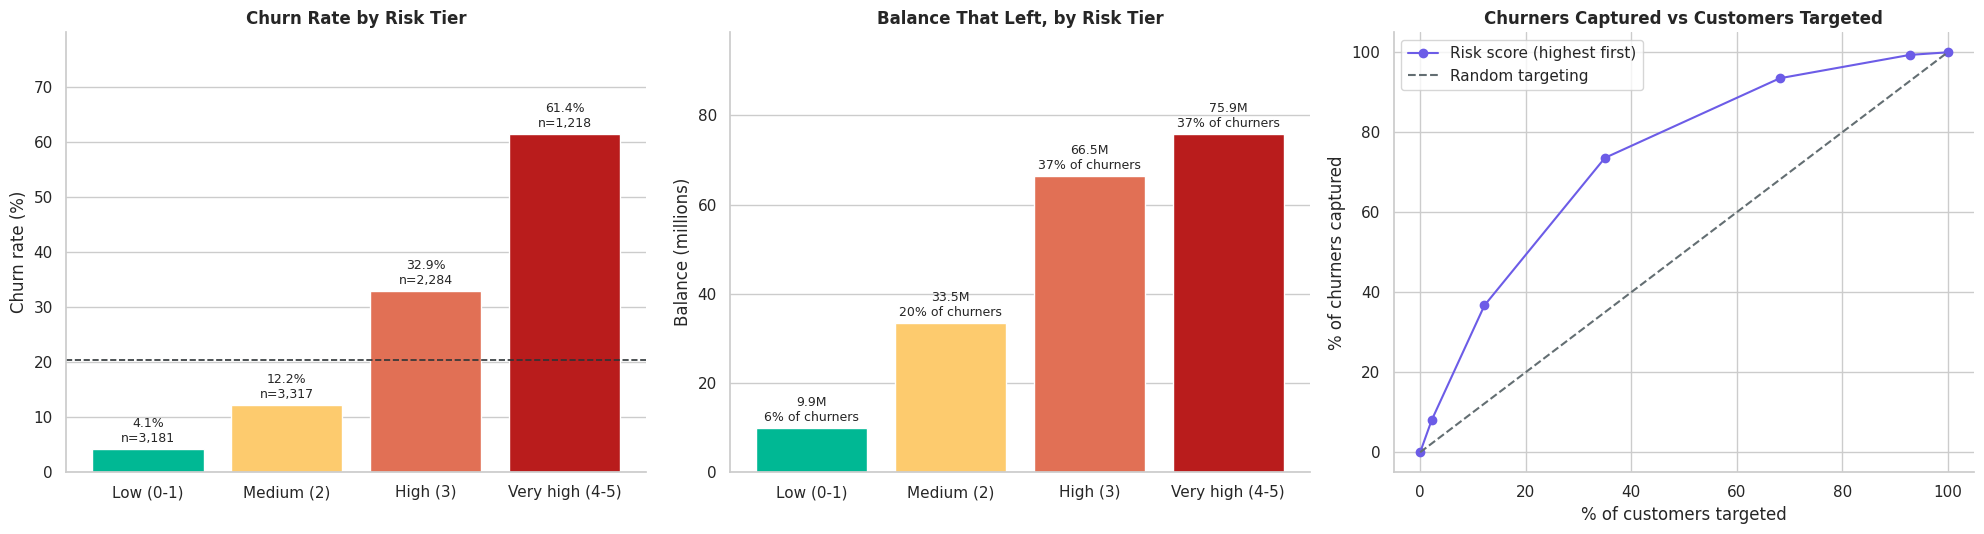

In [20]:
RISK_FLAGS = {
    "Aged 40-64":           "CASE WHEN Age BETWEEN 40 AND 64 THEN 1 ELSE 0 END",
    "Inactive member":      "CASE WHEN IsActiveMember = 0 THEN 1 ELSE 0 END",
    "1 or 3-4 products":    "CASE WHEN NumOfProducts <> 2 THEN 1 ELSE 0 END",
    "Germany":              "CASE WHEN Geography = 'Germany' THEN 1 ELSE 0 END",
    "Female":               "CASE WHEN Gender = 'Female' THEN 1 ELSE 0 END",
}
flag_sql = ",\n           ".join(f"{expr} AS f{i}" for i, expr in enumerate(RISK_FLAGS.values()))
points_sql = " + ".join(f"f{i}" for i in range(len(RISK_FLAGS)))

risk_by_points = run_sql(f"""
WITH flagged AS (
    SELECT CustomerId, churned, balance_at_risk, Balance,
           {flag_sql}
    FROM v_customers
), scored AS (
    SELECT *, ({points_sql}) AS risk_points FROM flagged
)
SELECT risk_points,
       COUNT(*)                                            AS customers,
       SUM(churned)                                        AS exited,
       ROUND(100.0 * AVG(churned), 2)                      AS churn_rate_pct,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)  AS share_of_customers_pct,
       ROUND(100.0 * SUM(churned) / SUM(SUM(churned)) OVER (), 2) AS share_of_churners_pct,
       ROUND(SUM(balance_at_risk), 0)                      AS balance_of_exited
FROM scored
GROUP BY risk_points
ORDER BY risk_points
""")
display(risk_by_points)

# Tiering
def tier_of(p):
    return "Low (0-1)" if p <= 1 else ("Medium (2)" if p == 2 else ("High (3)" if p == 3 else "Very high (4-5)"))
risk_by_points["Tier"] = risk_by_points["risk_points"].map(tier_of)
TIER_ORDER = ["Low (0-1)", "Medium (2)", "High (3)", "Very high (4-5)"]
tier = risk_by_points.groupby("Tier").agg(customers=("customers", "sum"), exited=("exited", "sum"),
                                          balance_of_exited=("balance_of_exited", "sum")).reindex(TIER_ORDER)
tier["churn_rate_pct"] = tier["exited"] / tier["customers"] * 100
tier["share_of_customers_pct"] = tier["customers"] / tier["customers"].sum() * 100
tier["share_of_churners_pct"] = tier["exited"] / tier["exited"].sum() * 100
tier["lift_vs_overall"] = tier["churn_rate_pct"] / OVERALL
tier = tier.reset_index()
display(tier)

# Cumulative capture ("gains") from the highest risk score downward
gains = risk_by_points.sort_values("risk_points", ascending=False).copy()
gains["cum_customers_pct"] = gains["share_of_customers_pct"].cumsum()
gains["cum_churners_pct"] = gains["share_of_churners_pct"].cumsum()
gains = pd.concat([pd.DataFrame({"risk_points": [np.nan], "cum_customers_pct": [0.0], "cum_churners_pct": [0.0]}), gains[["risk_points", "cum_customers_pct", "cum_churners_pct"]]])

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
tcolors = ["#00B894", "#FDCB6E", "#E17055", "#B91C1C"]
bar_panel(axes[0], tier["Tier"], tier["churn_rate_pct"], "Churn Rate by Risk Tier", ylabel="Churn rate (%)", fmt="{:.1f}%", colors=tcolors,
          extra=[f"n={n:,.0f}" for n in tier["customers"]], ylim_pad=1.3)
axes[0].axhline(OVERALL, color="#2D3436", linestyle="--", linewidth=1.2)
bar_panel(axes[1], tier["Tier"], tier["balance_of_exited"] / 1e6, "Balance That Left, by Risk Tier", ylabel="Balance (millions)", fmt="{:,.1f}M", colors=tcolors,
          extra=[f"{s:.0f}% of churners" for s in tier["share_of_churners_pct"]], ylim_pad=1.3)
axes[2].plot(gains["cum_customers_pct"], gains["cum_churners_pct"], marker="o", color="#6C5CE7", label="Risk score (highest first)")
axes[2].plot([0, 100], [0, 100], linestyle="--", color="#636e72", label="Random targeting")
axes[2].set_title("Churners Captured vs Customers Targeted", fontweight="bold")
axes[2].set_xlabel("% of customers targeted"); axes[2].set_ylabel("% of churners captured"); axes[2].legend(); sns.despine(ax=axes[2])
plt.tight_layout(); plt.show()

top2 = tier.set_index("Tier").loc[["High (3)", "Very high (4-5)"]]
hi_cust, hi_churn, hi_bal = top2["share_of_customers_pct"].sum(), top2["share_of_churners_pct"].sum(), top2["balance_of_exited"].sum()
hi_rate = top2["exited"].sum() / top2["customers"].sum() * 100
FINDINGS.update({"high_tier_customers_pct": hi_cust, "high_tier_churners_pct": hi_churn, "high_tier_rate": hi_rate,
                 "high_tier_balance": hi_bal, "low_tier_rate": float(tier.loc[tier["Tier"] == "Low (0-1)", "churn_rate_pct"].iloc[0])})
show_banner(
    "Where the churn is concentrated",
    f"The <strong>High</strong> and <strong>Very high</strong> tiers contain <strong>{hi_cust:.1f}%</strong> of customers but <strong>{hi_churn:.1f}%</strong> of all churners "
    f"(churn rate <strong>{hi_rate:.1f}%</strong> vs {FINDINGS['low_tier_rate']:.1f}% in the Low tier). These customers hold <strong>{amount(hi_bal/1e6, 1)}M</strong> of the {amount(FINDINGS['balance_of_exited']/1e6, 1)}M that left. "
    "A retention team that contacts only these tiers reaches most of the at-risk balance with a fraction of the effort.",
    color="orange", icon="🎯"
)

,Geography,Active,Product_Group,age_band,customers,exited,churn_rate_pct,share_of_all_churners_pct,balance_of_exited
0,Germany,Inactive,1 product,Aged 40-64,361,264,73.10,13.00,"31,812,420.00"
1,France,Inactive,1 product,Aged 40-64,491,271,55.20,13.30,"19,717,642.00"
2,Spain,Inactive,1 product,Aged 40-64,227,119,52.40,5.80,"7,985,644.00"
3,Germany,Active,1 product,Aged 40-64,260,133,51.20,6.50,"16,001,015.00"
4,Germany,Inactive,1 product,Other ages,359,111,30.90,5.40,"13,409,951.00"
5,Germany,Inactive,2 products,Aged 40-64,172,51,29.70,2.50,"6,001,476.00"
6,France,Active,1 product,Aged 40-64,479,138,28.80,6.80,"9,326,709.00"
7,Spain,Inactive,2 products,Aged 40-64,168,39,23.20,1.90,"3,139,962.00"
8,Spain,Active,1 product,Aged 40-64,267,55,20.60,2.70,"4,547,007.00"
9,Germany,Active,1 product,Other ages,369,70,19.00,3.40,"8,501,782.00"


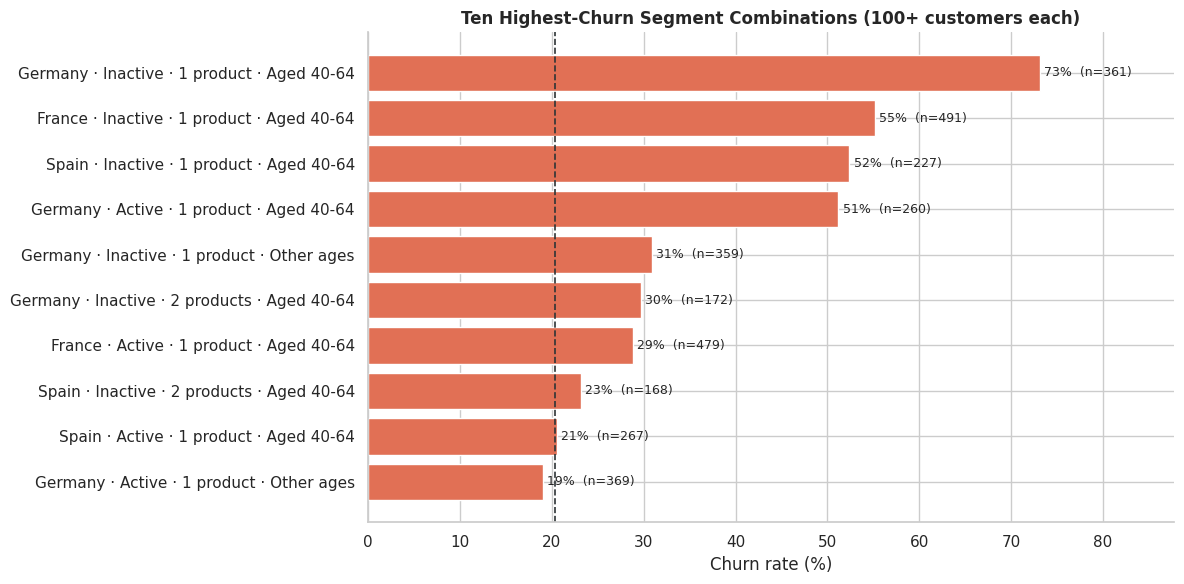

In [21]:
# Highest-churn segment combinations (SQL, groups with 100+ customers)
combo = run_sql("""
WITH seg AS (
    SELECT Geography, Active, Product_Group,
           CASE WHEN Age BETWEEN 40 AND 64 THEN 'Aged 40-64' ELSE 'Other ages' END AS age_band,
           COUNT(*)                         AS customers,
           SUM(churned)                     AS exited,
           SUM(balance_at_risk)             AS balance_of_exited
    FROM v_customers
    GROUP BY 1, 2, 3, 4
    HAVING COUNT(*) >= 100
)
SELECT Geography, Active, Product_Group, age_band, customers, exited,
       ROUND(100.0 * exited / customers, 1)                              AS churn_rate_pct,
       ROUND(100.0 * exited / (SELECT SUM(churned) FROM v_customers), 1) AS share_of_all_churners_pct,
       ROUND(balance_of_exited, 0)                                       AS balance_of_exited
FROM seg
ORDER BY churn_rate_pct DESC
LIMIT 10
""")
display(combo)

lab = combo["Geography"] + " · " + combo["Active"] + " · " + combo["Product_Group"] + " · " + combo["age_band"]
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(lab[::-1], combo["churn_rate_pct"][::-1], color="#E17055")
ax.bar_label(bars, labels=[f"{r:.0f}%  (n={n:,})" for r, n in zip(combo["churn_rate_pct"][::-1], combo["customers"][::-1])], padding=3, fontsize=9)
ax.axvline(OVERALL, color="#2D3436", linestyle="--", linewidth=1.2)
ax.set_xlim(0, combo["churn_rate_pct"].max() * 1.2)
ax.set_title("Ten Highest-Churn Segment Combinations (100+ customers each)", fontweight="bold"); ax.set_xlabel("Churn rate (%)"); sns.despine()
plt.tight_layout(); plt.show()

worst = combo.iloc[0]
FINDINGS.update({"worst_combo": f"{worst['Geography']} · {worst['Active']} · {worst['Product_Group']} · {worst['age_band']}",
                 "worst_combo_rate": worst["churn_rate_pct"], "worst_combo_n": int(worst["customers"])})
show_banner(
    "Highest-risk profiles",
    f"The riskiest large profile is <strong>{html.escape(FINDINGS['worst_combo'])}</strong>: a churn rate of <strong>{worst['churn_rate_pct']:.0f}%</strong> among {int(worst['customers']):,} customers. "
    "Profiles like these are where a targeted retention offer, a call from a relationship manager or a product review is most likely to matter. Combinations are small, so treat the exact rates as indicative.",
    color="pink", icon="🧭"
)

## 14. Predictive modelling: ranking customers by churn risk

The goal is a model that **ranks customers by their probability of leaving**, so retention effort can start with the highest-risk customers. The workflow keeps evaluation honest:

1. Identifiers and the leakage-prone columns (`Complain`, `Satisfaction_Score`) are excluded.
2. The data is split **80% train / 20% test** (stratified). The test set is used **once**, at the end.
3. **Logistic Regression, Random Forest and Gradient Boosting** are compared with 5-fold stratified cross-validation on the training set; the best mean ROC-AUC wins.
4. The decision threshold is tuned on **out-of-fold training predictions**, never on the test set.
5. The preprocessing sits inside a scikit-learn **pipeline**, so scaling and encoding are learned from training data only.

In [22]:
LEAKAGE_COLS = ["Complain", "Satisfaction_Score"]
ID_COLS = ["RowNumber", "CustomerId", "Surname"]

model_df = bank.copy()
model_df["NumOfProducts"] = model_df["NumOfProducts"].astype(str)      # product count is categorical, not a straight line

cat_features = ["Geography", "Gender", "Card_Type", "NumOfProducts"]
num_features = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary", "Points_Earned", "HasCrCard", "IsActiveMember", "Has_Balance"]

X = model_df[cat_features + num_features]
y = model_df["Exited"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Excluded identifiers:", ID_COLS)
print("Excluded as leakage / uninformative:", LEAKAGE_COLS)
print("Categorical predictors:", cat_features)
print("Numeric predictors:", num_features)
print(f"\nTrain: {len(X_train):,} customers, churn rate {y_train.mean()*100:.2f}%")
print(f"Test : {len(X_test):,} customers, churn rate {y_test.mean()*100:.2f}%")

show_cards([
    {"title": "Training set", "body": "Used to fit preprocessing and models, compare candidates through cross-validation, and choose the decision threshold from out-of-fold predictions.", "color": "blue", "icon": "🛠️"},
    {"title": "Test set", "body": "A held-out sample used once for the final performance estimate after every modelling choice is made.", "color": "pink", "icon": "🔒"},
    {"title": "Data leakage", "body": "Information that would not be available when the prediction is made, or information from the test set, enters training or selection. It inflates performance and then fails in practice.", "color": "red", "icon": "🚫"},
], columns=3)

Excluded identifiers: ['RowNumber', 'CustomerId', 'Surname']
Excluded as leakage / uninformative: ['Complain', 'Satisfaction_Score']
Categorical predictors: ['Geography', 'Gender', 'Card_Type', 'NumOfProducts']
Numeric predictors: ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary', 'Points_Earned', 'HasCrCard', 'IsActiveMember', 'Has_Balance']

Train: 8,000 customers, churn rate 20.38%
Test : 2,000 customers, churn rate 20.40%


,Model,ROC-AUC (mean),ROC-AUC (std),Avg precision (mean),Avg precision (std)
0,Random Forest,0.86,0.01,0.69,0.01
1,Gradient Boosting,0.86,0.01,0.69,0.02
2,Logistic Regression,0.83,0.01,0.61,0.02


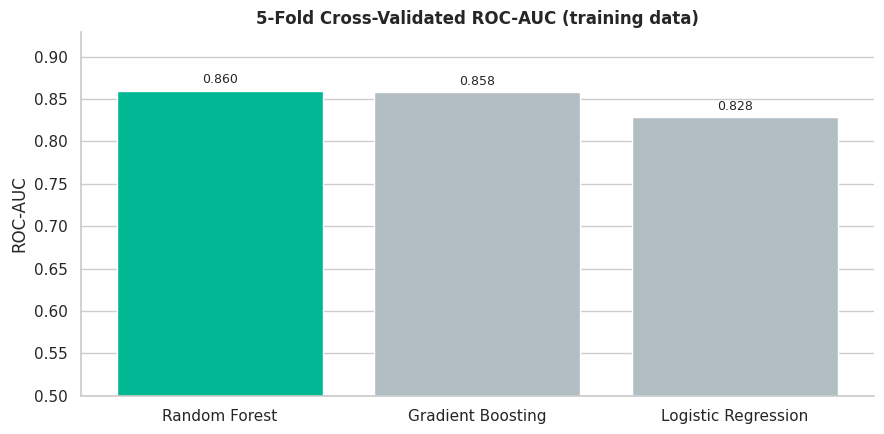

In [23]:
#Baseline: predict "stays" for everyone
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
base_acc = accuracy_score(y_test, dummy_pred)
base_rec = recall_score(y_test, dummy_pred, zero_division=0)

show_banner(
    "Baseline finding",
    f"Predicting that every customer stays gives <strong>{base_acc:.1%} accuracy</strong> but <strong>{base_rec:.1%} recall</strong> for customers who exit. "
    "It is right most of the time simply because most customers stay, and it finds no churners. This is why accuracy alone is not used to judge the model.",
    color="yellow", icon="⚖️"
)

# Candidate models share the same preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06, max_iter=250, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, est in candidates.items():
    pipe = Pipeline([("prep", preprocessor), ("model", est)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring={"roc_auc": "roc_auc", "avg_precision": "average_precision"}, n_jobs=1)
    cv_rows.append({"Model": name, "ROC-AUC (mean)": res["test_roc_auc"].mean(), "ROC-AUC (std)": res["test_roc_auc"].std(),
                    "Avg precision (mean)": res["test_avg_precision"].mean(), "Avg precision (std)": res["test_avg_precision"].std()})
cv_results = pd.DataFrame(cv_rows).sort_values("ROC-AUC (mean)", ascending=False).reset_index(drop=True)
display(cv_results)

best_name = cv_results.loc[0, "Model"]
best_pipe = Pipeline([("prep", preprocessor), ("model", candidates[best_name])])

fig, ax = plt.subplots(figsize=(9, 4.5))
bar_panel(ax, cv_results["Model"], cv_results["ROC-AUC (mean)"], "5-Fold Cross-Validated ROC-AUC (training data)", ylabel="ROC-AUC", fmt="{:.3f}",
          colors=["#00B894" if m == best_name else "#B2BEC3" for m in cv_results["Model"]], ylim_pad=1.1)
ax.set_ylim(0.5, cv_results["ROC-AUC (mean)"].max() * 1.08)
plt.tight_layout(); plt.show()

show_banner(
    "Model selection",
    f"<strong>{html.escape(best_name)}</strong> has the highest mean ROC-AUC ({cv_results.loc[0, 'ROC-AUC (mean)']:.3f} ± {cv_results.loc[0, 'ROC-AUC (std)']:.3f} across folds) and is selected. "
    + (f"The gap to the runner-up ({cv_results.loc[1, 'Model']}, {cv_results.loc[1, 'ROC-AUC (mean)']:.3f}) is smaller than the fold-to-fold variation, so the two are effectively tied and the choice is not clear-cut."
       if (cv_results.loc[0, 'ROC-AUC (mean)'] - cv_results.loc[1, 'ROC-AUC (mean)']) < cv_results.loc[0, 'ROC-AUC (std)'] else
       f"It is clearly ahead of the runner-up ({cv_results.loc[1, 'Model']}, {cv_results.loc[1, 'ROC-AUC (mean)']:.3f})."),
    color="green", icon="🏆"
)

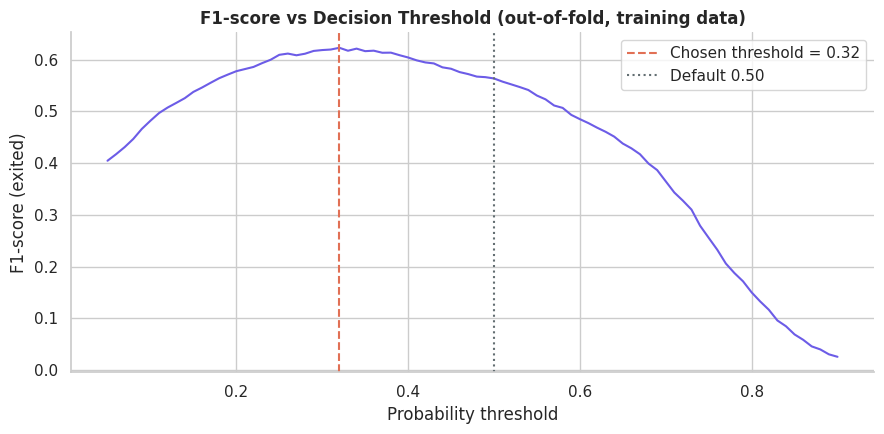

,Setting,Accuracy,Precision (exited),Recall (exited),F1 (exited)
0,Majority-class baseline,0.80,0.00,0.00,0.00
1,Model at threshold 0.50,0.87,0.81,0.46,0.59
2,Model at tuned threshold 0.32,0.84,0.60,0.69,0.64


Test ROC-AUC: 0.870 | Test average precision: 0.712 (no-skill = 0.204)


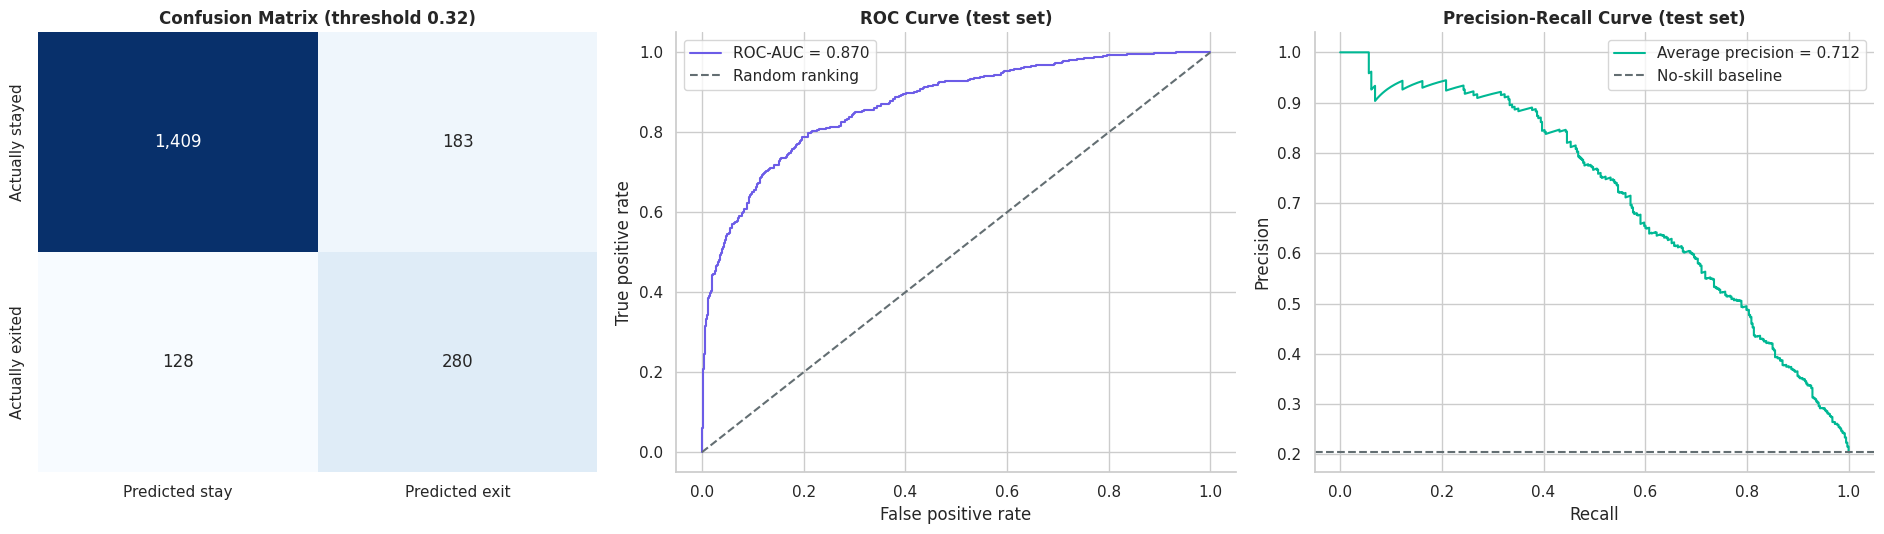

In [24]:
# Threshold tuning on out-of-fold training predictions (the test set is not touched)
oof_prob = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
grid = np.linspace(0.05, 0.90, 86)
f1_grid = np.array([f1_score(y_train, (oof_prob >= t).astype(int), zero_division=0) for t in grid])
best_threshold = float(grid[f1_grid.argmax()])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(grid, f1_grid, color="#6C5CE7")
ax.axvline(best_threshold, color="#E17055", linestyle="--", label=f"Chosen threshold = {best_threshold:.2f}")
ax.axvline(0.5, color="#636e72", linestyle=":", label="Default 0.50")
ax.set_title("F1-score vs Decision Threshold (out-of-fold, training data)", fontweight="bold")
ax.set_xlabel("Probability threshold"); ax.set_ylabel("F1-score (exited)"); ax.legend(); sns.despine()
plt.tight_layout(); plt.show()

# Final fit and one-time test evaluation
best_pipe.fit(X_train, y_train)
y_prob = best_pipe.predict_proba(X_test)[:, 1]

def metric_row(label, pred):
    return {"Setting": label, "Accuracy": accuracy_score(y_test, pred), "Precision (exited)": precision_score(y_test, pred, zero_division=0),
            "Recall (exited)": recall_score(y_test, pred, zero_division=0), "F1 (exited)": f1_score(y_test, pred, zero_division=0)}

metrics_tbl = pd.DataFrame([
    metric_row("Majority-class baseline", dummy_pred),
    metric_row("Model at threshold 0.50", (y_prob >= 0.5).astype(int)),
    metric_row(f"Model at tuned threshold {best_threshold:.2f}", (y_prob >= best_threshold).astype(int)),
])
display(metrics_tbl)

test_auc = roc_auc_score(y_test, y_prob)
test_ap = average_precision_score(y_test, y_prob)
y_pred = (y_prob >= best_threshold).astype(int)
tn_, fp_, fn_, tp_ = confusion_matrix(y_test, y_pred).ravel()
print(f"Test ROC-AUC: {test_auc:.3f} | Test average precision: {test_ap:.3f} (no-skill = {y_test.mean():.3f})")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
sns.heatmap(np.array([[tn_, fp_], [fn_, tp_]]), annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Predicted stay", "Predicted exit"], yticklabels=["Actually stayed", "Actually exited"])
axes[0].set_title(f"Confusion Matrix (threshold {best_threshold:.2f})", fontweight="bold")
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color="#6C5CE7", label=f"ROC-AUC = {test_auc:.3f}"); axes[1].plot([0, 1], [0, 1], "--", color="#636e72", label="Random ranking")
axes[1].set_title("ROC Curve (test set)", fontweight="bold"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend()
prec_c, rec_c, _ = precision_recall_curve(y_test, y_prob)
axes[2].plot(rec_c, prec_c, color="#00B894", label=f"Average precision = {test_ap:.3f}"); axes[2].axhline(y_test.mean(), color="#636e72", linestyle="--", label="No-skill baseline")
axes[2].set_title("Precision-Recall Curve (test set)", fontweight="bold"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend()
for ax in axes[1:]: sns.despine(ax=ax)
plt.tight_layout(); plt.show()

m_tuned = metrics_tbl.iloc[2]
FINDINGS.update({"best_model": best_name, "test_auc": test_auc, "test_ap": test_ap, "threshold": best_threshold,
                 "test_precision": m_tuned["Precision (exited)"], "test_recall": m_tuned["Recall (exited)"], "test_f1": m_tuned["F1 (exited)"],
                 "test_accuracy": m_tuned["Accuracy"], "base_acc": base_acc, "cv_auc": cv_results.loc[0, "ROC-AUC (mean)"]})

show_cards([
    {"title": "Ranking quality", "body": f"ROC-AUC <strong>{test_auc:.3f}</strong> on unseen customers (cross-validated {cv_results.loc[0, 'ROC-AUC (mean)']:.3f}). A random ranking scores 0.50.", "color": "green", "icon": "📈"},
    {"title": "Churners found", "body": f"Recall <strong>{m_tuned['Recall (exited)']:.1%}</strong>: the model flags {tp_:,} of the {tp_ + fn_:,} customers who left.", "color": "orange", "icon": "🔎"},
    {"title": "Alert quality", "body": f"Precision <strong>{m_tuned['Precision (exited)']:.1%}</strong>: {m_tuned['Precision (exited)']*100:.0f} of every 100 flagged customers actually left; the rest are false alarms ({fp_:,}).", "color": "pink", "icon": "🔔"},
    {"title": "Accuracy in context", "body": f"Accuracy <strong>{m_tuned['Accuracy']:.1%}</strong> vs <strong>{base_acc:.1%}</strong> for 'everyone stays': a gain of only {(m_tuned['Accuracy'] - base_acc)*100:.1f} pp, while recall rises from {base_rec:.0%} to {m_tuned['Recall (exited)']:.0%}.", "color": "blue", "icon": "⚖️"},
], columns=4)

,Feature,AUC drop,Std
0,Number of products,0.15,0.01
1,Age,0.11,0.01
2,Active member,0.02,0.00
3,Geography,0.02,0.00
4,Balance,0.02,0.00
5,Has a balance,0.01,0.00
6,Gender,0.01,0.00
7,Points earned,0.00,0.00
8,Card type,0.00,0.00
9,Credit score,0.00,0.00


,decile,customers,exited,avg_score,churn_rate_pct,lift,cum_churners_captured_pct
0,1,200,168,0.72,84.00,4.12,41.18
1,2,200,86,0.44,43.00,2.11,62.25
2,3,200,56,0.30,28.00,1.37,75.98
3,4,200,30,0.21,15.00,0.74,83.33
4,5,200,25,0.15,12.50,0.61,89.46
5,6,200,14,0.11,7.00,0.34,92.89
6,7,200,13,0.08,6.50,0.32,96.08
7,8,200,10,0.06,5.00,0.25,98.53
8,9,200,4,0.03,2.00,0.10,99.51
9,10,200,2,0.01,1.00,0.05,100.00


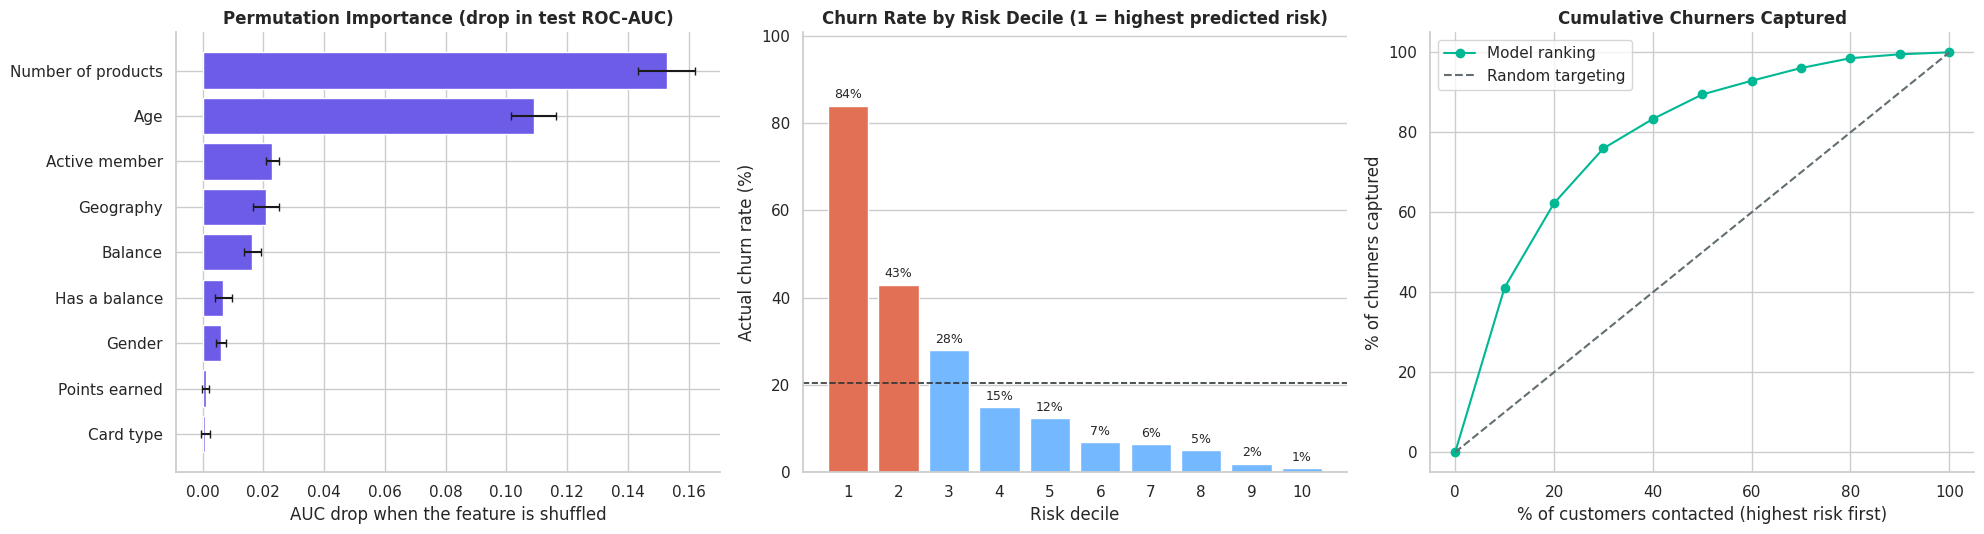

In [25]:
# What drives the model? Permutation importance on the test set
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"Feature": X_test.columns, "AUC drop": perm.importances_mean, "Std": perm.importances_std}).sort_values("AUC drop", ascending=False).reset_index(drop=True)
imp["Feature"] = imp["Feature"].replace({"NumOfProducts": "Number of products", "IsActiveMember": "Active member", "Has_Balance": "Has a balance",
                                         "HasCrCard": "Has credit card", "Points_Earned": "Points earned", "EstimatedSalary": "Estimated salary",
                                         "CreditScore": "Credit score", "Card_Type": "Card type"})
display(imp)

# Decile lift on the test set
lift = pd.DataFrame({"y": y_test.to_numpy(), "p": y_prob})
lift["decile"] = pd.qcut(lift["p"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
lift_tbl = lift.groupby("decile").agg(customers=("y", "size"), exited=("y", "sum"), avg_score=("p", "mean")).reset_index()
lift_tbl["churn_rate_pct"] = lift_tbl["exited"] / lift_tbl["customers"] * 100
lift_tbl["lift"] = lift_tbl["churn_rate_pct"] / (y_test.mean() * 100)
lift_tbl["cum_churners_captured_pct"] = lift_tbl["exited"].cumsum() / lift_tbl["exited"].sum() * 100
display(lift_tbl)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
top_imp = imp.head(9)
bars = axes[0].barh(top_imp["Feature"][::-1], top_imp["AUC drop"][::-1], xerr=top_imp["Std"][::-1], color="#6C5CE7", capsize=3)
axes[0].set_title("Permutation Importance (drop in test ROC-AUC)", fontweight="bold"); axes[0].set_xlabel("AUC drop when the feature is shuffled")
bar_panel(axes[1], lift_tbl["decile"], lift_tbl["churn_rate_pct"], "Churn Rate by Risk Decile (1 = highest predicted risk)", xlabel="Risk decile",
          ylabel="Actual churn rate (%)", fmt="{:.0f}%", colors=["#E17055" if d <= 2 else "#74B9FF" for d in lift_tbl["decile"]], ylim_pad=1.2)
axes[1].axhline(y_test.mean() * 100, color="#2D3436", linestyle="--", linewidth=1.2)
axes[2].plot([0] + list(lift_tbl["decile"] * 10), [0] + list(lift_tbl["cum_churners_captured_pct"]), marker="o", color="#00B894", label="Model ranking")
axes[2].plot([0, 100], [0, 100], "--", color="#636e72", label="Random targeting")
axes[2].set_title("Cumulative Churners Captured", fontweight="bold"); axes[2].set_xlabel("% of customers contacted (highest risk first)"); axes[2].set_ylabel("% of churners captured"); axes[2].legend()
for ax in (axes[0], axes[1], axes[2]): sns.despine(ax=ax)
plt.tight_layout(); plt.show()

top2_capture = lift_tbl.loc[lift_tbl["decile"] == 2, "cum_churners_captured_pct"].iloc[0]
top1_lift = lift_tbl.loc[lift_tbl["decile"] == 1, "lift"].iloc[0]
FINDINGS.update({"top_features": imp["Feature"].head(3).tolist(), "top_decile_lift": top1_lift, "top20_capture": top2_capture,
                 "top_decile_rate": lift_tbl.loc[lift_tbl["decile"] == 1, "churn_rate_pct"].iloc[0]})

show_banner(
    "How the model can be used",
    f"The most influential features are <strong>{html.escape(', '.join(FINDINGS['top_features']))}</strong>, which agrees with the segment and odds-ratio analysis. "
    f"The top-risk decile churns at <strong>{FINDINGS['top_decile_rate']:.0f}%</strong> ({top1_lift:.1f}x the average), and contacting the top 20% of customers by score would reach about "
    f"<strong>{top2_capture:.0f}%</strong> of churners. The score is a <strong>prioritisation tool</strong>: it ranks who to contact first, it does not show that a contact will stop a customer leaving.",
    color="purple", icon="🎯"
)

In [26]:
# Sensitivity: what if the leakage column were allowed?
leak_cat, leak_num = cat_features, num_features + ["Complain"]
leak_pre = ColumnTransformer([("num", StandardScaler(), leak_num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), leak_cat)])
leak_pipe = Pipeline([("prep", leak_pre), ("model", candidates[best_name])])
Xl = model_df[leak_cat + leak_num]
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(Xl, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
leak_pipe.fit(Xl_tr, yl_tr)
leak_auc = roc_auc_score(yl_te, leak_pipe.predict_proba(Xl_te)[:, 1])
FINDINGS["leak_auc"] = leak_auc

sens = pd.DataFrame({"Model": ["Without Complain (used in this notebook)", "With Complain (leakage)"], "Test ROC-AUC": [test_auc, leak_auc]})
display(sens)
show_banner(
    "Why Complain was excluded",
    f"Adding <code>Complain</code> lifts the test ROC-AUC from <strong>{test_auc:.3f}</strong> to <strong>{leak_auc:.3f}</strong>. That jump does not mean the model became better at "
    "anticipating churn; it means the model can read the answer from a column that records the outcome. A model like this would look excellent in testing and be of little use for finding customers "
    "<em>before</em> they leave.",
    color="red", icon="🚫"
)

,Model,Test ROC-AUC
0,Without Complain (used in this notebook),0.87
1,With Complain (leakage),1.00


## 15. Business findings and recommendations

This section turns the results above into decisions. Every number is read from the analysis that produced it, so the text updates if the data changes. Findings are **associations**, not proven causes, and the dataset has limits that are listed at the end.

In [27]:
F = FINDINGS

show_banner(
    "Headline",
    f"<strong>{F['churn_rate']:.1f}%</strong> of the bank's {F['customers']:,} customers left ({F['exited']:,} customers), taking <strong>{amount(F['balance_of_exited']/1e6, 1)}M</strong> "
    f"({F['balance_share']:.1f}%) of all balances with them. Churn is not spread evenly: it is concentrated among <strong>middle-aged customers, inactive members, customers with one or three-plus products, "
    f"and customers in {F['geo_hi']}</strong>. A simple five-factor score puts <strong>{F['high_tier_churners_pct']:.0f}%</strong> of churners into the <strong>{F['high_tier_customers_pct']:.0f}%</strong> of customers rated High or Very high, "
    f"and a leakage-free model reaches a test ROC-AUC of <strong>{F['test_auc']:.2f}</strong>.",
    color="purple", icon="🏁"
)

findings = [
    {"title": "Age", "icon": "🎂", "color": "orange",
     "body": f"Churn peaks in the <strong>{F['peak_age_group']}</strong> group at <strong>{F['peak_age_rate']:.1f}%</strong> vs {F['young_rate']:.1f}% at 18-25 and {F['senior_rate']:.1f}% at 66+. "
             f"Adjusted odds at 46-55 are {F['or_age4655']:.1f}x those at 36-45. The relationship is a hump, not a straight line."},
    {"title": "Products", "icon": "📦", "color": "teal",
     "body": f"Two products is the safest position (<strong>{F['prod2_rate']:.1f}%</strong> churn) vs {F['prod1_rate']:.1f}% with one. Customers with three or four products churn at "
             f"{F['prod3_rate']:.0f}% and {F['prod4_rate']:.0f}% (only {F['prod3_n'] + F['prod4_n']:,} customers), so the product mix itself deserves review."},
    {"title": "Activity", "icon": "💤", "color": "blue",
     "body": f"Inactive members churn at <strong>{F['inactive_rate']:.1f}%</strong> vs {F['active_rate']:.1f}% for active members; the gap holds in every product group and almost every age band."},
    {"title": "Geography & gender", "icon": "🌍", "color": "pink",
     "body": f"{F['geo_hi']} churns at <strong>{F['geo_hi_rate']:.1f}%</strong> vs {F['geo_lo_rate']:.1f}% in the lowest country, and women at {F['female_rate']:.1f}% vs {F['male_rate']:.1f}% for men. Both persist after adjustment (odds ratios {F['or_germany']:.2f} and {F['or_female']:.2f})."},
    {"title": "Balances", "icon": "💰", "color": "green",
     "body": f"Higher balances are not protective: leavers hold {F['balance_share']:.1f}% of all balances while being {F['churn_rate']:.1f}% of customers. Customers who hold no balance at all churn less."},
    {"title": "Complaints", "icon": "📣", "color": "red",
     "body": f"{F['complain_churn']:.1f}% of complainers left vs {F['nocomplain_churn']:.2f}% of others, and the column matches the outcome for {F['complain_agree_pct']:.1f}% of customers. "
             f"It is treated as leakage; satisfaction scores show no link to churn (p {fmt_p(F['sat_p'])})."},
    {"title": "Not informative", "icon": "➖", "color": "slate",
     "body": f"Little or no churn difference for {', '.join(F['flat_dims']) or 'none'}. Credit score and estimated salary also add little, so retention targeting should not be built on them."},
    {"title": "Risk model", "icon": "🤖", "color": "purple",
     "body": f"{F['best_model']}: test ROC-AUC <strong>{F['test_auc']:.3f}</strong>, recall {F['test_recall']:.0%} and precision {F['test_precision']:.0%} at threshold {F['threshold']:.2f}. "
             f"The top 20% of customers by score contain about {F['top20_capture']:.0f}% of churners."},
]
show_cards(findings, columns=2)

In [28]:
recs = pd.DataFrame([
    ["1", "Targeted retention for middle-aged, inactive customers", f"Customers aged 40-64 who are inactive (highest-risk profile: {F['worst_combo']}, {F['worst_combo_rate']:.0f}% churn)",
     "Relationship-manager calls, re-activation offers, review of fees and products", "High"],
    ["2", "Move one-product customers to a second product", f"Single-product customers ({F['prod1_rate']:.0f}% churn vs {F['prod2_rate']:.0f}% with two)",
     "Cross-sell a complementary product; test it with a control group before scaling", "High"],
    ["3", "Investigate the 3-4 product bundles", f"Customers with 3 or 4 products ({F['prod3_n'] + F['prod4_n']:,} customers, {F['prod3_rate']:.0f}-{F['prod4_rate']:.0f}% churn)",
     "Review pricing, fees and service quality for bundled customers; find out why they leave", "High"],
    ["4", "Country-level review", f"{F['geo_hi']} ({F['geo_hi_rate']:.0f}% churn)",
     "Compare competitor offers, service channels and product pricing; interview recent leavers", "Medium"],
    ["5", "Daily activity monitoring", f"Inactive members ({F['inactive_rate']:.0f}% churn vs {F['active_rate']:.0f}%)",
     "Trigger an outreach when a customer's activity drops; track reactivation rate", "Medium"],
    ["6", "Use the risk score to prioritise outreach", f"High and Very high tiers ({F['high_tier_customers_pct']:.0f}% of customers, {F['high_tier_churners_pct']:.0f}% of churners)",
     "Send a ranked contact list to the retention team; measure the save rate with a holdout group", "Medium"],
    ["7", "Fix the complaint data before using it", "Complain and Satisfaction Score",
     "Confirm when each field is recorded and what the score measures; if complaints precede exits, a complaint-resolution process is a real early-warning lever", "Data task"],
], columns=["#", "Action", "Target group", "What to do", "Priority"])
display(recs)

show_banner(
    "How to validate the recommendations",
    "Everything in this notebook is observational. Before committing budget, run a <strong>controlled retention test</strong>: contact a random half of the high-risk customers, hold back the other half, "
    "and compare exits after a fixed period. Only that comparison shows whether an action <em>reduces</em> churn rather than just flagging customers who would have left anyway.",
    color="teal", icon="🧭"
)

show_banner(
    "Limitations",
    "<ul><li>The data is one snapshot with no dates, so churn timing, trends and seasonality cannot be analysed.</li>"
    "<li>Provenance is undocumented and several columns behave like simulated data (evenly spread salary and tenure, a satisfaction score unrelated to everything), so findings illustrate the method rather than describe a real bank.</li>"
    "<li>No currency is given, so balances and salaries are shown as plain amounts.</li>"
    "<li>Risk tiers were designed on the same data they describe; the model results use a held-out test set, but a single 2,000-customer test split still carries sampling error.</li>"
    "<li>Customers with three or four products are few, so their churn rates are uncertain.</li>"
    "<li>The model was not tuned for business cost; the threshold maximises F1, not profit. The cost of a missed churner and of a wasted contact should set the real threshold.</li></ul>",
    color="yellow", icon="⚠️"
)

,#,Action,Target group,What to do,Priority
0,1,"Targeted retention for middle-aged, inactive customers","Customers aged 40-64 who are inactive (highest-risk profile: Germany · Inactive · 1 product · Aged 40-64, 73% churn)","Relationship-manager calls, re-activation offers, review of fees and products",High
1,2,Move one-product customers to a second product,Single-product customers (28% churn vs 8% with two),Cross-sell a complementary product; test it with a control group before scaling,High
2,3,Investigate the 3-4 product bundles,"Customers with 3 or 4 products (326 customers, 83-100% churn)","Review pricing, fees and service quality for bundled customers; find out why they leave",High
3,4,Country-level review,Germany (32% churn),"Compare competitor offers, service channels and product pricing; interview recent leavers",Medium
4,5,Daily activity monitoring,Inactive members (27% churn vs 14%),Trigger an outreach when a customer's activity drops; track reactivation rate,Medium
5,6,Use the risk score to prioritise outreach,"High and Very high tiers (35% of customers, 74% of churners)",Send a ranked contact list to the retention team; measure the save rate with a holdout group,Medium
6,7,Fix the complaint data before using it,Complain and Satisfaction Score,"Confirm when each field is recorded and what the score measures; if complaints precede exits, a complaint-resolution...",Data task


## 16. Conclusion

The summary below brings together the distinct findings without repeating the same metrics in several places.

In [29]:
conclusion_cards = [
    {"title": "1. Data quality & profile", "icon": "🧹", "color": "blue",
     "body": f"<strong>{len(raw):,}</strong> customers × <strong>{raw.shape[1]}</strong> source columns, no missing values or duplicates. "
             f"<strong>{F['zero_balance_pct']:.0f}%</strong> of customers hold a zero balance, and <code>Complain</code> nearly duplicates the target."},
    {"title": "2. Scale of churn", "icon": "📉", "color": "red",
     "body": f"<strong>{F['churn_rate']:.1f}%</strong> of customers left, carrying <strong>{F['balance_share']:.1f}%</strong> of balances. A model predicting 'stays' for everyone would be {F['base_acc']:.1%} accurate while finding no churners."},
    {"title": "3. Who leaves", "icon": "👥", "color": "orange",
     "body": f"Middle-aged customers (peak {F['peak_age_group']}), inactive members, one- or three-plus-product holders, {F['geo_hi']} and women. Largest single spread: <strong>{html.escape(str(F['spread_top']))}</strong> ({F['spread_top_pp']:.0f} pp)."},
    {"title": "4. What holds after adjustment", "icon": "🔍", "color": "teal",
     "body": f"Age, product count, activity, geography and gender all remain after adjustment. Balance size, credit score and salary add little."},
    {"title": "5. Complaints", "icon": "📣", "color": "pink",
     "body": f"Complaint status almost determines churn ({F['complain_churn']:.1f}% vs {F['nocomplain_churn']:.2f}%) and is treated as leakage. Satisfaction score is unrelated to churn."},
    {"title": "6. Risk segmentation", "icon": "🎯", "color": "purple",
     "body": f"A five-factor score puts {F['high_tier_churners_pct']:.0f}% of churners in the top {F['high_tier_customers_pct']:.0f}% of customers (churn {F['high_tier_rate']:.0f}% vs {F['low_tier_rate']:.0f}% in the Low tier)."},
    {"title": "7. Predictive model", "icon": "🤖", "color": "green",
     "body": f"{F['best_model']} reaches a test ROC-AUC of <strong>{F['test_auc']:.3f}</strong> without leakage ({F['leak_auc']:.3f} with <code>Complain</code>). It ranks customers for outreach; it does not prove why they leave."},
    {"title": "8. Next steps", "icon": "🧭", "color": "slate",
     "body": "Confirm when complaints are recorded, run a controlled retention test on the high-risk tiers, review the 3-4 product bundles, and replace the F1 threshold with one based on the cost of a missed churner."},
]
show_cards(conclusion_cards, columns=2)

conn.close()
print("Analysis complete. Yeayyy!")

Analysis complete. Yeayyy!
